# TP3 — Redes Bayesianas: colisões de fauna com aeronaves (FAA, 2017–2025)

**Disciplina:** Fundamentos de Inteligência Artificial

**Grupo:** Arthur Fernandes (2020026800), Bruno Lima Soares (2022055785) e Eduarda Amaral (matrícula: _preencher_)

Neste trabalho montamos uma rede bayesiana discreta com os dados de colisões entre aeronaves e animais registradas
pela FAA, a agência de aviação civil dos Estados Unidos. O notebook segue a ordem das tarefas do enunciado. Primeiro
baixamos e tratamos os dados (Tarefa 1) e desenhamos à mão a rede que esperávamos encontrar (Tarefa 2). Depois
aprendemos a estrutura com Hill-Climbing + BIC e com o algoritmo de Chow-Liu (Tarefa 3), estimamos as tabelas de
probabilidade e fazemos as consultas (Tarefa 4). O trabalho termina com a explicação de uma predição específica
da rede (Tarefa 5).

**Como executar.** Basta rodar tudo de uma vez: no Colab, *Runtime → Run all*; no Jupyter, *Kernel → Restart & Run All*.
O próprio notebook instala as bibliotecas, baixa a base da FAA (cerca de 133 MB) e roda o script de tratamento. Se o
Colab pedir para reiniciar o ambiente depois de instalar o `pgmpy`, reinicie e rode tudo de novo. A execução leva de 5 a
10 minutos, quase todos gastos no download e na leitura da planilha. Essa leitura chega perto de 8 GB de RAM, o que
ainda cabe no Colab gratuito.

## 0. Configuração do ambiente

In [1]:
%pip install -q "pgmpy==1.1.2" pandas pyarrow python-calamine requests matplotlib scikit-learn jinja2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import subprocess
import sys
import time
import warnings
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pgmpy
from IPython.display import Markdown, display
from sklearn.metrics import mutual_info_score

assert pgmpy.__version__ == "1.1.2", f"pgmpy {pgmpy.__version__}: este notebook foi escrito para a versão 1.1.2"
# O próprio pgmpy importa uma classe que ele mesmo marcou como obsoleta; o aviso não se refere a este código.
warnings.filterwarnings("ignore", category=FutureWarning, module=r"pgmpy\..*")
warnings.filterwarnings("ignore", message="IProgress not found")  # barra de progresso do tqdm, irrelevante aqui

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Figuras e tabelas vão para o relatório quando o notebook roda dentro do repositório; senão, para pastas locais.
DESTINO = Path("../relatorio") if Path("../relatorio/figuras").exists() else Path(".")
FIG_DIR, TAB_DIR = DESTINO / "figuras", DESTINO / "tabelas"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})

def salvar_fig(fig, nome):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{nome}.{ext}", bbox_inches="tight")

def _br(texto):
    # 1,234.5 -> 1.234,5
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")

def _formatar_coluna(col):
    if pd.api.types.is_bool_dtype(col):
        return col.map({True: "sim", False: "não"})
    if pd.api.types.is_integer_dtype(col):
        return col.map(lambda v: _br(f"{v:,}"))
    if pd.api.types.is_float_dtype(col):
        finitos = col[np.isfinite(col)]
        casas = max([len(f"{v:.4f}".rstrip("0").split(".")[1]) for v in finitos] or [0])
        return col.map(lambda v: _br(f"{v:,.{casas}f}") if np.isfinite(v)
                       else "—" if np.isnan(v) else ("−∞" if v < 0 else "∞"))
    return col

def salvar_tab(tabela, nome, **kw):
    # Tabelas para o relatório: números no formato brasileiro, sem índice.
    t = tabela.copy()
    for c in t.columns:
        t[c] = _formatar_coluna(t[c])
    (TAB_DIR / f"{nome}.tex").write_text(t.to_latex(index=False, escape=True, **kw), encoding="utf-8")

print({"python": sys.version.split()[0], "pgmpy": pgmpy.__version__, "pandas": pd.__version__,
       "numpy": np.__version__, "networkx": nx.__version__, "saída": str(DESTINO.resolve())})

{'python': '3.12.3', 'pgmpy': '1.1.2', 'pandas': '3.1.1', 'numpy': '2.5.4', 'networkx': '3.7', 'saída': '/home/bruno_admin/tp3-redes-bayesianas/relatorio'}


## 1. Coleta e tratamento dos dados

Os dados vêm do site da FAA (`https://wildlife.faa.gov`), que disponibiliza a base inteira num arquivo
`database_excel.zip` com a planilha `Public.xlsx`. O script abaixo baixa esse arquivo e lê a planilha uma vez só,
guardando uma cópia em parquet para as próximas execuções. Em seguida, ele fica só com os anos de 2017 a 2025, descarta
os registros sem nível de dano ou sem fase do voo, agrupa as categorias e discretiza a altura. O script é salvo em disco
e executado com o mesmo Python do notebook.

In [3]:
%%writefile coletar_birdstrikes.py
#!/usr/bin/env python3
"""
Coleta e limpeza da FAA National Wildlife Strike Database para o TP de Redes Bayesianas.

Fonte: https://wildlife.faa.gov  ->  "Download Excel"
       arquivo estático: https://wildlife.faa.gov/assets/database_excel.zip  (~133 MB, contém Public.xlsx)
       dicionário de campos: https://wildlife.faa.gov/assets/fieldlist.pdf

Uso (da raiz do repo):
    pip install pandas requests python-calamine pyarrow
    python coletar_birdstrikes.py                      # baixa, lê, limpa
    python coletar_birdstrikes.py --ano-min 2017 --ano-max 2025   # recorte (padrão)
    python coletar_birdstrikes.py --sem-download       # reaproveita o zip já baixado

Saídas:
    dados/brutos/database_excel.zip          download original
    dados/brutos/strikes_bruto.parquet       planilha inteira convertida (leitura do Excel só acontece 1 vez)
    dados/processados/strikes_rede.csv       1 linha por colisão, só variáveis discretas para a rede
    dados/processados/relatorio.md           valores originais x agrupados, faltantes, dano por estado
"""
from __future__ import annotations

import argparse
import re
import sys
import zipfile
from pathlib import Path

import pandas as pd

URL = "https://wildlife.faa.gov/assets/database_excel.zip"
RAIZ = Path("dados")
BRUTOS, PROC = RAIZ / "brutos", RAIZ / "processados"
ZIP = BRUTOS / "database_excel.zip"
CACHE = BRUTOS / "strikes_bruto.parquet"

# Colunas usadas (nomes do fieldlist.pdf). Texto livre e dados de quem reportou ficam de fora.
COLUNAS = [
    "INDEX_NR", "INCIDENT_YEAR", "INCIDENT_MONTH", "TIME_OF_DAY", "PHASE_OF_FLIGHT",
    "HEIGHT", "SPEED", "SKY", "PRECIPITATION", "AC_MASS", "TYPE_ENG",
    "SPECIES", "SIZE", "NUM_STRUCK", "WARNED", "DAMAGE_LEVEL", "EFFECT",
    "ING_ENG1", "ING_ENG2", "ING_ENG3", "ING_ENG4",
]
# Alguns campos mudaram de nome entre versões da base; aceitamos os dois.
SINONIMOS = {
    "PHASE_OF_FLT": "PHASE_OF_FLIGHT",
    "PRECIP": "PRECIPITATION",
    "BIRDS_STRUCK": "NUM_STRUCK",
    "DAMAGE": "DAMAGE_LEVEL",
    "INDEX NR": "INDEX_NR",
}


# --------------------------------------------------------------------------- #
# 1. Download e leitura
# --------------------------------------------------------------------------- #
def baixar():
    import requests

    BRUTOS.mkdir(parents=True, exist_ok=True)
    print(f"Baixando {URL} (~133 MB)...")
    with requests.get(URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        feito = 0
        with open(ZIP, "wb") as f:
            for bloco in r.iter_content(1 << 20):
                f.write(bloco)
                feito += len(bloco)
                if total:
                    print(f"\r  {feito / total:6.1%}", end="")
    print("\n  ok")


def ler_planilha() -> pd.DataFrame:
    if CACHE.exists():
        print(f"Lendo cache {CACHE}")
        return pd.read_parquet(CACHE)
    if not ZIP.exists():
        sys.exit(f"{ZIP} não existe. Rode sem --sem-download.")
    print("Lendo o Excel (360 mil linhas; com python-calamine leva ~1–2 min)...")
    with zipfile.ZipFile(ZIP) as z:
        nome = next(n for n in z.namelist() if n.lower().endswith(".xlsx"))
        with z.open(nome) as f:
            try:
                df = pd.read_excel(f, engine="calamine", dtype=str)
            except (ImportError, ValueError):
                print("  python-calamine ausente: usando openpyxl (bem mais lento, ~10 min)")
                df = pd.read_excel(f, engine="openpyxl", dtype=str)
    df.columns = [str(c).strip().upper() for c in df.columns]
    df = df.rename(columns={k: v for k, v in SINONIMOS.items() if k in df.columns and v not in df.columns})
    try:
        df.to_parquet(CACHE, index=False)
        print(f"  cache salvo em {CACHE}")
    except ImportError:
        print("  (instale pyarrow para salvar o cache e não reler o Excel)")
    return df


# --------------------------------------------------------------------------- #
# 2. Funções de agrupamento
# --------------------------------------------------------------------------- #
def norm(s: pd.Series) -> pd.Series:
    """Texto em minúsculas, sem espaços extras; vazios viram NA."""
    s = s.astype("string").str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
    return s.replace({"": pd.NA, "nan": pd.NA, "none specified": pd.NA, "unknown": pd.NA})


def num(s: pd.Series) -> pd.Series:
    return pd.to_numeric(s, errors="coerce")


def booleano(s: pd.Series) -> pd.Series:
    m = {"true": True, "1": True, "y": True, "yes": True, "-1": True,
         "false": False, "0": False, "n": False, "no": False}
    return norm(s).map(m)


def por_regras(s: pd.Series, regras: list[tuple[str, str]], padrao="outro", faltante="desconhecido"):
    """Aplica a primeira regex que casar. Regras em ordem de prioridade."""
    def f(v):
        if pd.isna(v):
            return faltante
        for rotulo, padrao_re in regras:
            if re.search(padrao_re, v):
                return rotulo
        return padrao
    return norm(s).map(f)


FASE = [
    ("corrida_decolagem", r"take.?off|takeoff"),
    ("subida", r"climb|departure"),
    ("rota", r"en ?route|local"),
    ("aproximacao", r"approach|descent|arrival"),
    ("corrida_pouso", r"landing"),
    ("solo_taxi", r"taxi|parked"),
]
PERIODO = [("amanhecer", r"dawn"), ("dia", r"^day"), ("anoitecer", r"dusk"), ("noite", r"night")]
CEU = [("sem_nuvens", r"no cloud"), ("algumas_nuvens", r"some cloud"), ("encoberto", r"overcast")]
TAMANHO = [("pequeno", r"small"), ("medio", r"medium"), ("grande", r"large")]
QTD = [("um", r"^1$"), ("2_a_10", r"2.?-.?10"), ("mais_de_10", r"11|over|more")]
MOTOR = [  # códigos A–F do fieldlist.pdf
    ("pistao", r"^a$"), ("jato", r"^[bd]$"), ("turboelice", r"^c$"),
    ("helicoptero", r"^f$"),
    ("desconhecido", r"^[ey]$"),  # planador/outro: só 4 casos
]
EFEITO = [
    ("desligamento_motor", r"engine shut"),
    ("decolagem_abortada", r"abort"),
    ("pouso_precaucao", r"precaution"),
    ("nenhum", r"^none$"),
]
NAO_AVES = [
    # aves cujo nome contém palavra de mamífero (killdeer, rock pigeon, cattle egret, fox sparrow...)
    ("ave", r"\bbird|killdeer|pigeon|dove|egret|sparrow|heron|hawk|owl|gull|duck|goose"),
    ("morcego", r"\bbats?\b"),
    ("terrestre", r"\b(deer|coyotes?|fox(es)?|rabbits?|jackrabbits?|hares?|skunks?|raccoons?|armadillos?|dogs?|"
                  r"cats?|opossums?|woodchucks?|groundhogs?|squirrels?|muskrats?|beavers?|elk|moose|pronghorn|"
                  r"antelopes?|cattle|horses?|pigs?|hogs?|bears?|marmots?|badgers?|minks?|otters?|porcupines?|"
                  r"turtles?|tortoises?|alligators?|snakes?|lizards?|iguanas?|terrapins?)\b"),
]


def dano(s: pd.Series) -> pd.Series:
    # N nenhum | M leve | M? indeterminado (houve dano) | S substancial | D destruído | vazio = desconhecido
    m = {"n": "nenhum", "m": "leve", "m?": "leve", "s": "grave", "d": "grave"}  # M? = houve dano, nível indeterminado
    return norm(s).map(m)


def tercis_com_zero(s: pd.Series, rot0: str, rotulos=("baixa", "media", "alta")) -> pd.Series:
    """Zero vira um estado próprio (no solo / parado); o resto em tercis, como pede o enunciado."""
    out = pd.Series("desconhecido", index=s.index, dtype="string")
    out[s == 0] = rot0
    pos = s > 0
    if pos.sum() > 3:
        cod = pd.qcut(s[pos], 3, labels=False, duplicates="drop")  # empates podem fundir faixas
        n = int(cod.max()) + 1
        nomes = list(rotulos) if n == 3 else [rotulos[0], rotulos[-1]][:n]
        out[pos] = cod.map(lambda c: nomes[int(c)])
    return out


# --------------------------------------------------------------------------- #
# 3. Limpeza
# --------------------------------------------------------------------------- #
def limpar(df: pd.DataFrame, ano_min: int, ano_max: int) -> tuple[pd.DataFrame, list[str]]:
    faltam = [c for c in COLUNAS if c not in df.columns]
    if faltam:
        print("ATENÇÃO, colunas não encontradas:", faltam)
        print("Colunas disponíveis:", ", ".join(df.columns))
    rel = [f"# Relatório — FAA Wildlife Strikes\n",
           f"- linhas na planilha: {len(df):,}; colunas: {df.shape[1]}"]

    d = df.copy()
    for c in COLUNAS:  # coluna ausente vira vazia (aparece como "desconhecido") em vez de quebrar
        if c not in d.columns:
            d[c] = pd.NA
    d["ano"] = num(d["INCIDENT_YEAR"])
    d = d[d["ano"].between(ano_min, ano_max)]
    rel.append(f"- de {ano_min} a {ano_max}: {len(d):,}")

    d["dano"] = dano(d["DAMAGE_LEVEL"])
    rel.append(f"- sem nível de dano informado (removidas): {d['dano'].isna().sum():,}")
    d = d[d["dano"].notna()].copy()
    # sem fase do voo = em geral carcaça achada na pista, sem relato do voo (quase tudo vira "desconhecido")
    sem_fase = norm(d["PHASE_OF_FLIGHT"]).isna()
    rel.append(f"- sem fase do voo (carcaças sem relato; removidas): {sem_fase.sum():,}")
    d = d[~sem_fase].copy()

    out = pd.DataFrame(index=d.index)
    out["id"] = d["INDEX_NR"]
    out["ano"] = d["ano"].astype(int)

    mes = num(d["INCIDENT_MONTH"])
    out["estacao"] = mes.map(lambda m: "desconhecido" if pd.isna(m) else
                             {12: "inverno", 1: "inverno", 2: "inverno", 3: "primavera", 4: "primavera",
                              5: "primavera", 6: "verao", 7: "verao", 8: "verao"}.get(int(m), "outono"))
    out["periodo"] = por_regras(d["TIME_OF_DAY"], PERIODO)
    out["fase_voo"] = por_regras(d["PHASE_OF_FLIGHT"], FASE)
    out["altura"] = tercis_com_zero(num(d["HEIGHT"]), "solo")
    out["ceu"] = por_regras(d["SKY"], CEU)

    massa = num(d["AC_MASS"])
    out["massa_aeronave"] = massa.map(lambda m: "desconhecido" if pd.isna(m) else
                                      ("leve" if m <= 2 else "media" if m == 3 else "pesada"))
    out["motor"] = por_regras(d["TYPE_ENG"], MOTOR)

    out["animal"] = por_regras(d["SPECIES"], NAO_AVES, padrao="ave", faltante="ave")
    out["tamanho_animal"] = por_regras(d["SIZE"], TAMANHO)
    out["qtd_atingida"] = por_regras(d["NUM_STRUCK"], QTD)
    out["avisado"] = booleano(d["WARNED"]).map({True: "sim", False: "nao"}).fillna("desconhecido")

    ing = pd.concat([booleano(d[c]) for c in ["ING_ENG1", "ING_ENG2", "ING_ENG3", "ING_ENG4"]], axis=1)
    out["ingestao_motor"] = ing.fillna(False).any(axis=1).map({True: "sim", False: "nao"})

    out["houve_dano"] = d["dano"].map({"nenhum": "nao", "leve": "sim", "grave": "sim"})
    out["nivel_dano"] = d["dano"]  # 3 estados; use se quiser trabalhar a gravidade
    out["efeito_voo"] = por_regras(d["EFFECT"], EFEITO, padrao="outro", faltante="nenhum")

    # ---- relatório: valores ORIGINAIS de cada coluna categórica (para conferir os agrupamentos)
    rel.append("\n## Valores originais (top 15) — conferir se os agrupamentos cobrem tudo")
    for c in ["TIME_OF_DAY", "PHASE_OF_FLIGHT", "SKY", "PRECIPITATION", "AC_MASS", "TYPE_ENG",
              "SIZE", "NUM_STRUCK", "WARNED", "DAMAGE_LEVEL", "EFFECT", "ING_ENG1"]:
        if c in df.columns:
            vc = df.loc[d.index, c].astype("string").fillna("<vazio>").value_counts().head(15)
            rel.append(f"\n### {c}\n```\n{vc.to_string()}\n```")
    for grupo in ["morcego", "terrestre"]:
        esp = d.loc[out["animal"].eq(grupo), "SPECIES"].value_counts().head(15)
        rel.append(f"\n### Espécies em '{grupo}' (top 15)\n```\n{esp.to_string()}\n```")

    return out, rel


def resumo(out: pd.DataFrame, rel: list[str]):
    rel.append(f"\n## Base final: {len(out):,} colisões, {out.shape[1] - 3} nós (+ nivel_dano extra)")
    rel.append("\n## Nível de dano por ano (%)\n```\n" +
               pd.crosstab(out["ano"], out["nivel_dano"], normalize="index").mul(100).round(1).to_string() + "\n```")
    for c in [c for c in out.columns if c not in ("id", "ano", "nivel_dano")]:
        t = pd.crosstab(out[c], out["nivel_dano"], margins=True, margins_name="total")
        pct = (t.div(t["total"], axis=0) * 100).round(1)
        tab = t[["total"]].join(pct.drop(columns="total").add_prefix("%"))
        rel.append(f"\n### {c}\n```\n{tab.to_string()}\n```")


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--sem-download", action="store_true")
    p.add_argument("--ano-min", type=int, default=2017)  # critério de dano estável a partir daqui
    p.add_argument("--ano-max", type=int, default=2025)  # 2026 ainda incompleto
    a = p.parse_args()
    if not a.sem_download and not ZIP.exists():
        baixar()
    df = ler_planilha()
    out, rel = limpar(df, a.ano_min, a.ano_max)
    resumo(out, rel)
    PROC.mkdir(parents=True, exist_ok=True)
    out.to_csv(PROC / "strikes_rede.csv", index=False)
    (PROC / "relatorio.md").write_text("\n".join(rel), encoding="utf-8")
    print(f"\nPronto: {PROC / 'strikes_rede.csv'} ({len(out):,} linhas) e {PROC / 'relatorio.md'}")


if __name__ == "__main__":
    main()

Overwriting coletar_birdstrikes.py


In [4]:
t0 = time.time()
proc = subprocess.run([sys.executable, "coletar_birdstrikes.py", "--ano-min", "2017", "--ano-max", "2025"],
                      capture_output=True, text=True)
print(proc.stdout[-2000:])
if proc.returncode != 0:
    print(proc.stderr[-3000:])
    raise RuntimeError("Falha na coleta. Se o site da FAA estiver fora do ar, veja a célula seguinte.")
print(f"Coleta e tratamento: {time.time() - t0:.0f} s")

Lendo cache dados/brutos/strikes_bruto.parquet

Pronto: dados/processados/strikes_rede.csv (72,877 linhas) e dados/processados/relatorio.md

Coleta e tratamento: 4 s


> **Se o download falhar** (por exemplo, com o site da FAA fora do ar), baixe o arquivo à mão em
> `https://wildlife.faa.gov/assets/database_excel.zip`, coloque-o em `dados/brutos/` e rode
> `subprocess.run([sys.executable, "coletar_birdstrikes.py", "--sem-download"], check=True)`.

In [5]:
relatorio_coleta = Path("dados/processados/relatorio.md").read_text(encoding="utf-8")
display(Markdown(relatorio_coleta.split("## Valores originais")[0]))

# Relatório — FAA Wildlife Strikes

- linhas na planilha: 360,384; colunas: 102
- de 2017 a 2025: 159,245
- sem nível de dano informado (removidas): 65,745
- sem fase do voo (carcaças sem relato; removidas): 20,623



## 2. Tarefa 1 — Domínio, pré-processamento e perguntas de interesse

A *National Wildlife Strike Database* reúne os relatos de colisões entre aeronaves e animais nos Estados Unidos,
enviados por pilotos, aeroportos, companhias aéreas e equipes de manutenção. Cada linha da base é uma colisão e traz
informações sobre o voo (fase, altura, condição do céu), sobre a aeronave (massa e tipo de motor), sobre o animal
(espécie, tamanho e quantos foram atingidos) e sobre as consequências (dano, ingestão pelo motor e efeito no voo).
Começamos o recorte em 2017 porque o critério de dano está estável desde então, e paramos em 2025 porque os dados de
2026 ainda estão incompletos.

A rede tem 14 variáveis, todas categóricas. A que mais nos interessa é `houve_dano`; a segunda é `efeito_voo`.
Deixamos `nivel_dano` (nenhum, leve ou grave) fora do aprendizado porque ela determina `houve_dano` por completo:
dano "nenhum" é a mesma coisa que `houve_dano = nao`. Com as duas na rede, o algoritmo encontraria uma dependência
perfeita que não acrescenta nada.

In [6]:
NOS = ["estacao", "periodo", "fase_voo", "altura", "ceu", "massa_aeronave", "motor", "animal",
       "tamanho_animal", "qtd_atingida", "avisado", "ingestao_motor", "houve_dano", "efeito_voo"]
STATE_NAMES = {
    "estacao": ["inverno", "primavera", "verao", "outono"],
    "periodo": ["amanhecer", "dia", "anoitecer", "noite", "desconhecido"],
    "fase_voo": ["solo_taxi", "corrida_decolagem", "subida", "rota", "aproximacao", "corrida_pouso"],
    "altura": ["solo", "baixa", "media", "alta", "desconhecido"],
    "ceu": ["sem_nuvens", "algumas_nuvens", "encoberto", "desconhecido"],
    "massa_aeronave": ["leve", "media", "pesada", "desconhecido"],
    "motor": ["pistao", "turboelice", "jato", "helicoptero", "desconhecido"],
    "animal": ["ave", "morcego", "terrestre"],
    "tamanho_animal": ["pequeno", "medio", "grande", "desconhecido"],
    "qtd_atingida": ["um", "dois_ou_mais"],
    "avisado": ["sim", "nao", "desconhecido"],
    "ingestao_motor": ["nao", "sim"],
    "houve_dano": ["nao", "sim"],
    "efeito_voo": ["nenhum", "pouso_precaucao", "decolagem_abortada", "desligamento_motor", "outro"],
}
ROTULOS = {"estacao": "Estação", "periodo": "Período", "fase_voo": "Fase do voo", "altura": "Altura",
           "ceu": "Céu", "massa_aeronave": "Massa da\naeronave", "motor": "Motor", "animal": "Animal",
           "tamanho_animal": "Tamanho\ndo animal", "qtd_atingida": "Quantidade\natingida", "avisado": "Aviso",
           "ingestao_motor": "Ingestão\nmotor", "houve_dano": "Houve dano", "efeito_voo": "Efeito\nno voo"}

def carregar_base(caminho):
    # Aceita também a versão do CSV alinhada com espaços.
    df = pd.read_csv(caminho, dtype=str, skipinitialspace=True)
    df.columns = df.columns.str.strip()
    df = df.apply(lambda s: s.str.strip())
    assert set(NOS) <= set(df.columns), set(NOS) - set(df.columns)
    assert df[NOS].notna().all().all(), "há valores faltantes não codificados"
    return df

def preparar(df):
    # O script deixa 4 estados em qtd_atingida. Juntamos "2 a 10" com "mais de 10" (só 347 colisões têm mais de 10)
    # e tiramos as poucas linhas sem quantidade, que deixariam linhas instáveis nas tabelas de probabilidade.
    assert set(df["qtd_atingida"]) <= {"um", "2_a_10", "mais_de_10", "desconhecido"}
    df = df[df["qtd_atingida"] != "desconhecido"].copy()
    df["qtd_atingida"] = df["qtd_atingida"].replace({"2_a_10": "dois_ou_mais", "mais_de_10": "dois_ou_mais"})
    for c in NOS:
        extras = set(df[c]) - set(STATE_NAMES[c])
        assert not extras, f"{c}: estados inesperados {extras}"
        df[c] = pd.Categorical(df[c], categories=STATE_NAMES[c])
    return df

df_script = carregar_base("dados/processados/strikes_rede.csv")
df = preparar(df_script)
dados = df[NOS]
print(f"{len(df_script):,} colisões saíram do script; {len(df_script) - len(df)} sem quantidade atingida foram removidas")
print(f"{len(df):,} colisões × {len(NOS)} nós")
if len(df_script) != 72_877:
    print("Aviso: a FAA atualizou a base desde 2026-11-14 (72.877 colisões); os números abaixo podem diferir do relatório.")
print(pd.crosstab(df["houve_dano"], df["nivel_dano"]))

72,877 colisões saíram do script; 65 sem quantidade atingida foram removidas
72,812 colisões × 14 nós
nivel_dano  grave  leve  nenhum
houve_dano                     
nao             0     0   67204
sim           405  5203       0


**Pré-processamento.** Removemos os registros sem o alvo (`DAMAGE_LEVEL`) ou sem a fase do voo. Quando falta a fase,
o registro quase sempre é de uma carcaça encontrada na pista, sem nenhum relato sobre o voo. Nas outras variáveis,
preferimos transformar o valor faltante num estado próprio, `desconhecido`, porque descartar essas linhas jogaria fora
metade da base só por causa da variável `avisado`. Essa escolha tem um custo, que aparece na Tarefa 3.

A quantidade de animais atingidos é a exceção. O script a entrega com quatro estados, mas só 347 colisões tinham mais
de 10 animais e só 65 não tinham a quantidade informada. Juntamos "2 a 10" e "mais de 10" num estado só,
`dois_ou_mais`, e removemos as 65 linhas sem quantidade. Elas criavam combinações de pais quase vazias nas tabelas de
probabilidade, com estimativas instáveis (40% de dano, calculados sobre 65 casos).

A única variável contínua que usamos é a altura (`HEIGHT`, em pés acima do solo). Altura zero virou o estado `solo`,
que reúne um terço das colisões. Os valores positivos foram divididos em três faixas por quantis (tercis), chamadas
`baixa`, `media` e `alta`, e os vazios viraram `desconhecido`. A massa da aeronave já vem da FAA como um código
ordinal de 1 a 5, que agrupamos em faixas de peso.

As categorias originais foram agrupadas com regras simples (expressões regulares) e renomeadas em português. A tabela
abaixo mostra o resultado, e o relatório gerado pelo script lista os valores originais de cada grupo.

In [7]:
ORIGEM = {"estacao": "INCIDENT_MONTH", "periodo": "TIME_OF_DAY", "fase_voo": "PHASE_OF_FLIGHT",
          "altura": "HEIGHT", "ceu": "SKY", "massa_aeronave": "AC_MASS", "motor": "TYPE_ENG",
          "animal": "SPECIES", "tamanho_animal": "SIZE", "qtd_atingida": "NUM_STRUCK", "avisado": "WARNED",
          "ingestao_motor": "ING_ENG1..4", "houve_dano": "DAMAGE_LEVEL", "efeito_voo": "EFFECT"}
tab_variaveis = pd.DataFrame([
    {"Nó": c, "Coluna FAA": ORIGEM[c], "Estados": len(STATE_NAMES[c]),
     "Contagens": ", ".join(f"{s} {n:,}".replace(",", ".") for s, n in df[c].value_counts().reindex(STATE_NAMES[c]).items()),
     "% desconhecido": round(100 * (df[c] == "desconhecido").mean(), 1)}
    for c in NOS])
salvar_tab(tab_variaveis, "tab_variaveis", column_format="llrp{7.2cm}r")
tab_variaveis

,Nó,Coluna FAA,Estados,Contagens,% desconhecido
0,estacao,INCIDENT_MONTH,4,"inverno 6.947, primavera 16.662, verao 23.837,...",0.0
1,periodo,TIME_OF_DAY,5,"amanhecer 2.236, dia 38.814, anoitecer 3.018, ...",7.4
2,fase_voo,PHASE_OF_FLIGHT,6,"solo_taxi 311, corrida_decolagem 8.640, subida...",0.0
3,altura,HEIGHT,5,"solo 22.698, baixa 11.339, media 11.426, alta ...",22.3
4,ceu,SKY,4,"sem_nuvens 28.924, algumas_nuvens 18.997, enco...",23.2
5,massa_aeronave,AC_MASS,4,"leve 11.053, media 7.768, pesada 53.537, desco...",0.6
6,motor,TYPE_ENG,5,"pistao 5.928, turboelice 2.611, jato 61.103, h...",0.8
7,animal,SPECIES,3,"ave 70.744, morcego 1.194, terrestre 874",0.0
8,tamanho_animal,SIZE,4,"pequeno 42.317, medio 8.610, grande 4.259, des...",24.2
9,qtd_atingida,NUM_STRUCK,2,"um 64.928, dois_ou_mais 7.884",0.0


In [8]:
# Limites dos tercis de altura, recalculados sobre os mesmos registros que o script manteve.
import coletar_birdstrikes as cb
bruto = pd.read_parquet("dados/brutos/strikes_bruto.parquet",  # só as colunas usadas: a base inteira ocupa ~1 GB
                        columns=["INCIDENT_YEAR", "DAMAGE_LEVEL", "PHASE_OF_FLIGHT", "HEIGHT"])
mantidos = (cb.num(bruto["INCIDENT_YEAR"]).between(2017, 2025) & cb.dano(bruto["DAMAGE_LEVEL"]).notna()
            & cb.norm(bruto["PHASE_OF_FLIGHT"]).notna())
altura_pes = cb.num(bruto.loc[mantidos, "HEIGHT"])
tercis = pd.qcut(altura_pes[altura_pes > 0], 3)
tab_tercis = pd.DataFrame({"Estado": ["solo", "baixa", "media", "alta", "desconhecido"],
                           "Faixa (pés)": ["0"] + [f"({i.left:.0f}, {i.right:.0f}]" for i in tercis.cat.categories] + ["vazio"],
                           "Colisões": [int((altura_pes == 0).sum()), *tercis.value_counts(sort=False).tolist(),
                                        int(altura_pes.isna().sum())]})
assert tab_tercis["Colisões"].tolist() == df_script["altura"].value_counts().reindex(tab_tercis["Estado"]).tolist()
tab_tercis["Colisões"] = df["altura"].value_counts().reindex(tab_tercis["Estado"]).tolist()  # base final
salvar_tab(tab_tercis, "tab_tercis_altura")
del bruto
tab_tercis

,Estado,Faixa (pés),Colisões
0,solo,0,22698
1,baixa,"(1, 350]",11339
2,media,"(350, 1700]",11426
3,alta,"(1700, 32000]",11081
4,desconhecido,vazio,16268


,Etapa,Registros
0,linhas na planilha,360384
1,de 2017 a 2025,159245
2,sem nível de dano informado (removidas),65745
3,sem fase do voo (carcaças sem relato; removidas),20623
4,sem quantidade atingida (removidas no notebook),65
5,base final,72812


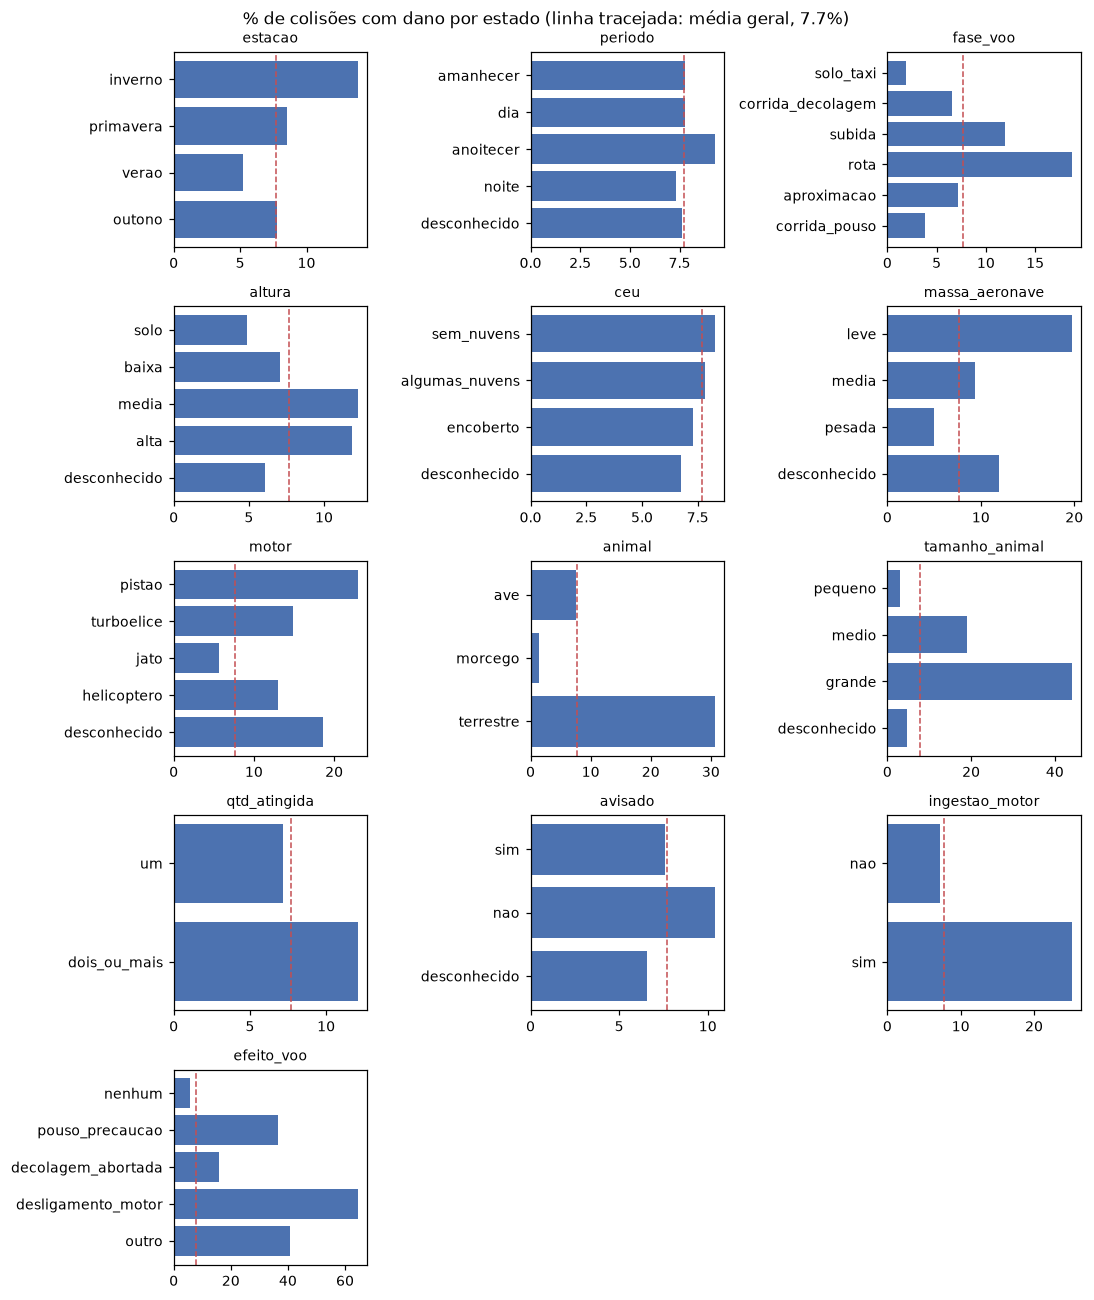

In [9]:
# Funil de registros (do relatório do script) e taxa de dano por estado de cada variável.
import re
funil = re.findall(r"- (.+?): ([\d,]+)", relatorio_coleta)
tab_funil = pd.DataFrame([(t, int(n.replace(",", ""))) for t, n in funil], columns=["Etapa", "Registros"])
tab_funil.loc[len(tab_funil)] = ["sem quantidade atingida (removidas no notebook)", len(df_script) - len(df)]
tab_funil.loc[len(tab_funil)] = ["base final", len(df)]
salvar_tab(tab_funil, "tab_funil")
display(tab_funil)

taxa_base = (df["houve_dano"] == "sim").mean()
preditoras = [c for c in NOS if c != "houve_dano"]
fig, eixos = plt.subplots(5, 3, figsize=(10, 12))
for ax, c in zip(eixos.flat, preditoras):
    taxa = df.groupby(c, observed=False)["houve_dano"].apply(lambda s: 100 * (s == "sim").mean())
    ax.barh(taxa.index.astype(str), taxa.values, color="#4C72B0")
    ax.axvline(100 * taxa_base, color="#C44E52", ls="--", lw=1)
    ax.set_title(c, fontsize=9)
    ax.invert_yaxis()
for ax in eixos.flat[len(preditoras):]:
    ax.axis("off")
fig.suptitle(f"% de colisões com dano por estado (linha tracejada: média geral, {100 * taxa_base:.1f}%)")
fig.tight_layout()
salvar_fig(fig, "fig_taxa_dano_por_estado")
plt.show()

**Discussão.** As maiores diferenças na taxa de dano aparecem nas variáveis ligadas à força do impacto e à
resistência da aeronave. Quando o animal é grande, há dano em 44,0% das colisões; quando é pequeno, em 2,9%. Mamíferos
terrestres causam dano em 30,7% dos casos, bem acima das aves (7,5%) e dos morcegos (1,4%). Do lado da aeronave, as
leves sofrem dano em 19,7% das colisões e as pesadas em 4,9%, e o motor a pistão (23,0%) fica muito acima do jato
(5,6%). A ingestão pelo motor multiplica a taxa por três e meio (25,1% contra 7,1%). Colisões em rota (18,7%) e na
subida (11,9%) também causam mais dano do que as da corrida de pouso (3,8%), quando a aeronave já está mais lenta.

O contexto do voo pesa menos. Para o período do dia e para o céu, todas as taxas ficam entre 6,7% e 9,3%, perto da
média geral de 7,7%. A estação é a exceção: no inverno a taxa chega a 13,9%, contra 5,2% no verão. Como nenhuma das
redes aprendidas liga a estação diretamente ao dano, esse efeito, se existir, precisa passar por outras variáveis.

Os estados `desconhecido` não se comportam como ruído neutro. Com motor desconhecido a taxa de dano é de 18,6%, e com
massa desconhecida, de 11,9%, as duas acima da média. Os relatos incompletos parecem vir de fontes e situações
diferentes das dos relatos completos, e a rede vai usar essa diferença como informação. Os tercis de altura também
chamam atenção: a faixa `baixa` vai só até 350 pés e a `alta` começa em 1.700, porque a maior parte das colisões
acontece perto do solo.

### Perguntas de interesse

Formulamos quatro perguntas para a rede responder, cada uma exigindo um tipo diferente de raciocínio.

**Q1.** Dado o perfil de uma colisão (aeronave, motor, animal e fase do voo), qual é a probabilidade de a aeronave
sofrer dano? É a pergunta preditiva principal.

**Q2.** Quando o motor ingere um animal, qual a chance de isso afetar o voo, com um pouso de precaução, uma decolagem
abortada ou o desligamento do motor?

**Q3.** No sentido contrário: se sabemos que o motor teve de ser desligado, o que provavelmente atingiu a aeronave?
Aqui olhamos o tamanho do animal e a quantidade atingida.

**Q4.** Se o manejo de fauna nos aeroportos conseguisse afastar os animais médios e grandes, quanto cairia o risco de
dano? Essa pergunta é sobre uma intervenção, `do(tamanho_animal = pequeno)`, e não só sobre uma observação.

## 3. Tarefa 2 — Estrutura elicitada manualmente

Antes de rodar qualquer algoritmo, desenhamos a rede que achávamos fazer sentido (a figura original está em
`INPUTS/rede_etapa2.png`). A ideia geral é que o contexto do voo influencia qual animal está no caminho, que o animal e
a aeronave determinam a ingestão pelo motor e o dano, e que o dano e a ingestão determinam o efeito no voo.

No contexto, a estação muda a nebulosidade (`estacao → ceu`) e a fauna presente, por causa de migrações e hibernação
(`estacao → animal`). O período do dia também muda o animal (`periodo → animal`), já que morcegos são noturnos e
mamíferos terrestres aparecem mais no amanhecer e no anoitecer. A fase do voo define a altura (`fase_voo → altura`):
na corrida de pouso a aeronave está no solo e em rota está alta. A altura, por sua vez, limita o tipo de animal
(`altura → animal`), porque mamíferos só são atingidos no solo. Ligamos ainda o céu ao aviso de fauna
(`ceu → avisado`), imaginando que a visibilidade ruim mudaria a frequência dos avisos.

O tipo de animal define o tamanho (`animal → tamanho_animal`), já que mamíferos terrestres costumam ser grandes e
morcegos são pequenos, e também quantos são atingidos (`animal → qtd_atingida`), pois aves voam em bando e mamíferos
andam sozinhos. Do lado da aeronave, a massa define o tipo de motor (`massa_aeronave → motor`): aviões leves usam
pistão e os pesados, jato. Um bando aumenta a chance de algum animal entrar no motor
(`qtd_atingida → ingestao_motor`), e os turbofans aspiram o ar à frente deles, ao contrário de hélices e rotores
(`motor → ingestao_motor`).

O dano depende do tamanho do animal, que define a energia do impacto (`tamanho_animal → houve_dano`), da quantidade
atingida (`qtd_atingida → houve_dano`), da massa da aeronave, porque as leves têm estrutura menos resistente
(`massa_aeronave → houve_dano`), e da ingestão, que pode danificar o motor (`ingestao_motor → houve_dano`). O efeito
no voo depende da ingestão, que pode levar ao desligamento do motor ou a um pouso de precaução
(`ingestao_motor → efeito_voo`), e do dano (`houve_dano → efeito_voo`). No total, são 17 arestas.

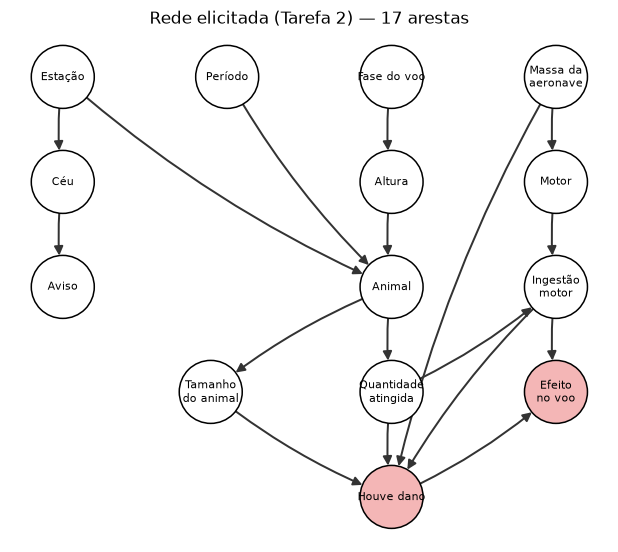

In [10]:
from pgmpy.base import DAG

ARESTAS_ELICITADAS = [
    ("estacao", "ceu"), ("ceu", "avisado"),
    ("estacao", "animal"), ("periodo", "animal"),
    ("fase_voo", "altura"), ("altura", "animal"),
    ("animal", "tamanho_animal"), ("animal", "qtd_atingida"),
    ("tamanho_animal", "houve_dano"), ("qtd_atingida", "houve_dano"),
    ("qtd_atingida", "ingestao_motor"),
    ("massa_aeronave", "motor"), ("motor", "ingestao_motor"),
    ("massa_aeronave", "houve_dano"),
    ("ingestao_motor", "houve_dano"), ("ingestao_motor", "efeito_voo"),
    ("houve_dano", "efeito_voo"),
]
dag_elic = DAG(ARESTAS_ELICITADAS)
dag_elic.add_nodes_from(NOS)
assert len(dag_elic.edges()) == 17 and nx.is_directed_acyclic_graph(dag_elic)

# Mesmo layout do desenho original, usado em todas as figuras de rede.
POS = {"estacao": (0, 5), "periodo": (2, 5), "fase_voo": (4, 5), "massa_aeronave": (6, 5),
       "ceu": (0, 4), "altura": (4, 4), "motor": (6, 4),
       "avisado": (0, 3), "animal": (4, 3), "ingestao_motor": (6, 3),
       "tamanho_animal": (1.8, 2), "qtd_atingida": (4, 2), "efeito_voo": (6, 2),
       "houve_dano": (4, 1)}
ALVOS = {"houve_dano", "efeito_voo"}

def desenhar(g, ax, titulo, cor_aresta=None, cor_no=None):
    cor_aresta = cor_aresta or {}
    cor_no = cor_no or {n: ("#F4B6B6" if n in ALVOS else "white") for n in g.nodes()}
    nx.draw_networkx_nodes(g, POS, ax=ax, node_size=1700, node_color=[cor_no[n] for n in g.nodes()],
                           edgecolors="black", linewidths=1)
    nx.draw_networkx_labels(g, POS, labels={n: ROTULOS[n] for n in g.nodes()}, font_size=7, ax=ax)
    # Arestas verticais longas atravessariam os nós do meio da coluna; elas ganham uma curva maior.
    def longa(e):
        (x1, y1), (x2, y2) = POS[e[0]], POS[e[1]]
        return abs(x1 - x2) < 0.5 and abs(y1 - y2) > 1
    for curva, arestas in ((0.08, [e for e in g.edges() if not longa(e)]), (0.35, [e for e in g.edges() if longa(e)])):
        nx.draw_networkx_edges(g, POS, edgelist=arestas, ax=ax, node_size=1700, arrows=True, arrowsize=12,
                               width=1.3, edge_color=[cor_aresta.get(e, "#333333") for e in arestas],
                               connectionstyle=f"arc3,rad={curva}")
    ax.set_title(titulo)
    ax.axis("off")

fig, ax = plt.subplots(figsize=(7, 6))
desenhar(dag_elic, ax, "Rede elicitada (Tarefa 2) — 17 arestas")
salvar_fig(fig, "fig_rede_elicitada")
plt.show()

## 4. Tarefa 3 — Aprendizado de estrutura

### 4.1 Hill-Climbing com score BIC

O Hill-Climbing começa com um grafo sem arestas. A cada passo, ele testa todas as mudanças locais possíveis (incluir,
remover ou inverter uma aresta, sem criar ciclos) e aplica a que mais melhora o score. Quando nenhuma mudança melhora
o score, ele para. O resultado é um ótimo local, que não é necessariamente o melhor grafo possível. O score que usamos
é o BIC:

$$\mathrm{BIC}(G) = \log P(D \mid \hat\theta_G) - \frac{k_G}{2}\log n.$$

O primeiro termo mede o quanto o grafo explica os dados (a log-verossimilhança, com os parâmetros estimados por máxima
verossimilhança). O segundo é uma penalidade que cresce com o número $k_G$ de parâmetros livres e com o tamanho $n$ da
base. Assim, uma aresta só entra se melhorar o ajuste o bastante para pagar os parâmetros que acrescenta. Usamos a
versão mais simples do algoritmo, sem lista tabu (`tabu_length=0`).

Hill-Climbing: 31 arestas em 0.2 s; grau de entrada máximo 3; 1,302 parâmetros livres
Pais de cada nó:
  estacao         ← ['altura', 'periodo']
  periodo         ← ['altura', 'fase_voo']
  fase_voo        ← ['altura', 'motor']
  altura          ← ['motor']
  ceu             ← ['altura', 'periodo']
  massa_aeronave  ← []
  motor           ← ['massa_aeronave']
  animal          ← ['altura', 'periodo', 'tamanho_animal']
  tamanho_animal  ← ['altura', 'avisado', 'ceu']
  qtd_atingida    ← ['houve_dano', 'periodo', 'tamanho_animal']
  avisado         ← ['altura', 'ceu', 'massa_aeronave']
  ingestao_motor  ← ['houve_dano', 'massa_aeronave', 'qtd_atingida']
  houve_dano      ← ['altura', 'massa_aeronave', 'tamanho_animal']
  efeito_voo      ← ['fase_voo', 'houve_dano', 'massa_aeronave']


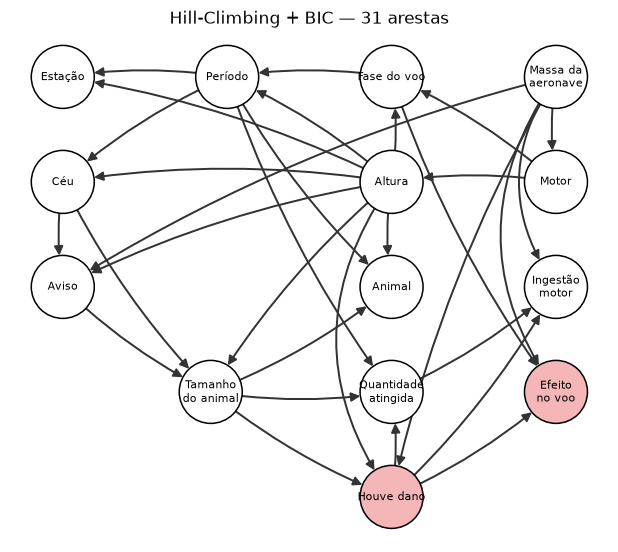

In [11]:
from pgmpy.causal_discovery import HillClimbSearch
from pgmpy.metrics import StructureScore

bic = StructureScore(scoring_method="bic-d")

class HillClimbing(HillClimbSearch):
    # O pgmpy guarda as operações candidatas num set, cuja ordem muda a cada execução do Python (o hash de strings é
    # aleatório). Quando duas operações empatam no BIC, o que acontece sempre que inverter uma aresta dá um grafo
    # equivalente, o max() fica com a primeira e a rede final pode mudar de uma execução para outra. Ordenar as
    # operações deixa o desempate fixo; o algoritmo continua o mesmo.
    def _legal_operations_dag(self, *args, **kwargs):
        return iter(sorted(super()._legal_operations_dag(*args, **kwargs), key=lambda op: op[0]))

def n_parametros(g):
    card = {c: len(STATE_NAMES[c]) for c in NOS}
    return sum((card[x] - 1) * int(np.prod([card[p] for p in g.predecessors(x)])) for x in g.nodes())

t0 = time.time()
hc = HillClimbing(scoring_method="bic-d", return_type="dag", tabu_length=0, show_progress=False).fit(dados)
dag_hc = hc.causal_graph_
dag_hc.add_nodes_from(NOS)
assert nx.is_directed_acyclic_graph(dag_hc)
print(f"Hill-Climbing: {len(dag_hc.edges())} arestas em {time.time() - t0:.1f} s; "
      f"grau de entrada máximo {max(d for _, d in dag_hc.in_degree())}; {n_parametros(dag_hc):,} parâmetros livres")
print("Pais de cada nó:")
for n in NOS:
    print(f"  {n:15s} ← {sorted(dag_hc.predecessors(n))}")

fig, ax = plt.subplots(figsize=(7, 6))
desenhar(dag_hc, ax, f"Hill-Climbing + BIC — {len(dag_hc.edges())} arestas")
salvar_fig(fig, "fig_rede_hc")
plt.show()

### 4.2 Hill-Climbing com ordem por camadas

O Hill-Climbing livre aceita qualquer direção de seta que melhore o BIC, e algumas das que ele escolhe não fazem
sentido físico (a seção 4.4 mostra quais). Para uma consulta comum isso não atrapalha, porque a distribuição conjunta
continua a mesma. Já as intervenções da Q4 e da Tarefa 5 dependem da direção das setas. Por isso rodamos uma segunda
busca, com o mesmo score, mas respeitando uma ordem entre grupos de variáveis.

As camadas seguem a ordem dos acontecimentos. Na primeira fica o contexto (estação, período e céu); na segunda, a
aeronave e o voo (massa, motor, fase, altura e aviso); na terceira, o animal encontrado (tipo, tamanho e quantidade);
nas três últimas, as consequências, uma por camada: ingestão, dano e efeito no voo. Uma seta nunca pode voltar para
uma camada anterior, e dentro da mesma camada a direção fica livre. No pgmpy isso se faz com
`ExpertKnowledge(temporal_order=...)`.

Esta é a rede que usamos nas Tarefas 4 e 5. A diferença de BIC para o Hill-Climbing livre mede quanto custa exigir essa
coerência.

HC por camadas: 31 arestas em 1.8 s; 1,345 parâmetros livres
BIC: livre -696,115.1; por camadas -697,125.0; custo da ordem 1,009.9
Setas do HC livre que a ordem proíbe: [('altura', 'ceu'), ('altura', 'estacao'), ('altura', 'periodo'), ('fase_voo', 'periodo'), ('houve_dano', 'ingestao_motor'), ('houve_dano', 'qtd_atingida')]
Pais de cada nó:
  estacao         ← ['ceu', 'periodo']
  periodo         ← ['ceu']
  fase_voo        ← ['altura', 'motor']
  altura          ← ['ceu', 'estacao', 'periodo']
  ceu             ← []
  massa_aeronave  ← ['altura', 'avisado']
  motor           ← ['altura', 'massa_aeronave']
  animal          ← ['altura', 'periodo', 'tamanho_animal']
  tamanho_animal  ← ['altura', 'avisado', 'ceu']
  qtd_atingida    ← ['periodo', 'tamanho_animal']
  avisado         ← ['altura', 'ceu']
  ingestao_motor  ← ['massa_aeronave', 'qtd_atingida', 'tamanho_animal']
  houve_dano      ← ['ingestao_motor', 'massa_aeronave', 'tamanho_animal']
  efeito_voo      ← ['fase_voo', 'houve_d

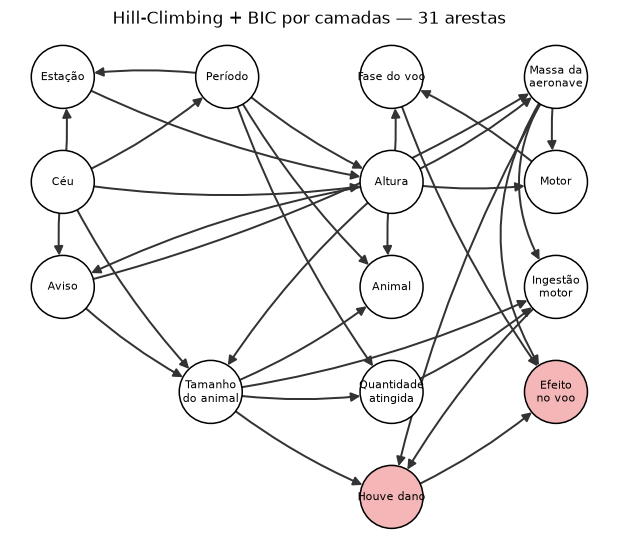

In [12]:
from pgmpy.causal_discovery import ExpertKnowledge

# Uma seta nunca pode voltar para uma camada anterior; dentro de uma camada, a direção fica livre.
CAMADAS = [
    ["estacao", "periodo", "ceu"],                                 # contexto
    ["massa_aeronave", "motor", "fase_voo", "altura", "avisado"],  # aeronave e voo
    ["animal", "tamanho_animal", "qtd_atingida"],                  # animal encontrado
    ["ingestao_motor"],                                            # consequências, em ordem
    ["houve_dano"],
    ["efeito_voo"],
]
assert sorted(sum(CAMADAS, [])) == sorted(NOS)
camada = {v: i for i, nos in enumerate(CAMADAS) for v in nos}

def hc_camadas(obrigatorias=()):
    conhecimento = ExpertKnowledge(temporal_order=CAMADAS, required_edges=list(obrigatorias))
    g = HillClimbing(scoring_method="bic-d", return_type="dag", tabu_length=0, show_progress=False,
                        expert_knowledge=conhecimento).fit(dados).causal_graph_
    g.add_nodes_from(NOS)
    assert nx.is_directed_acyclic_graph(g) and all(camada[a] <= camada[b] for a, b in g.edges())
    return g

t0 = time.time()
dag_cam = hc_camadas()
bic_livre, bic_cam = bic(X=dados, causal_graph=dag_hc), bic(X=dados, causal_graph=dag_cam)
print(f"HC por camadas: {len(dag_cam.edges())} arestas em {time.time() - t0:.1f} s; {n_parametros(dag_cam):,} parâmetros livres")
print(f"BIC: livre {bic_livre:,.1f}; por camadas {bic_cam:,.1f}; custo da ordem {bic_livre - bic_cam:,.1f}")
print("Setas do HC livre que a ordem proíbe:", sorted((a, b) for a, b in dag_hc.edges() if camada[a] > camada[b]))
print("Pais de cada nó:")
for n in NOS:
    print(f"  {n:15s} ← {sorted(dag_cam.predecessors(n))}")

fig, ax = plt.subplots(figsize=(7, 6))
desenhar(dag_cam, ax, f"Hill-Climbing + BIC por camadas — {len(dag_cam.edges())} arestas")
salvar_fig(fig, "fig_rede_hc_camadas")
plt.show()

### 4.3 Chow-Liu

O algoritmo de Chow-Liu procura a melhor rede entre as que têm formato de árvore. Ele calcula a informação mútua
$I(X_i;X_j)$ de cada par de variáveis, que mede o quanto conhecer uma reduz a incerteza sobre a outra, e monta a árvore
que liga todas as variáveis com a maior soma de informação mútua. Depois escolhe uma raiz e orienta as arestas a partir
dela. O resultado sempre tem $n-1 = 13$ arestas, e cada nó tem no máximo um pai.

A escolha da raiz não muda o BIC. Numa árvore nenhum nó tem dois pais, então todas as orientações descrevem as mesmas
independências condicionais. Escolhemos, por isso, a raiz que deixa mais arestas orientadas do mesmo jeito que na rede
elicitada, o que facilita a comparação.

Chow-Liu: 11.2 s


Raiz escolhida: massa_aeronave (4 arestas com a orientação da elicitada); BIC idêntico para as 14 raízes: -709,953.5
Arestas: [('altura', 'ceu'), ('altura', 'estacao'), ('altura', 'periodo'), ('ceu', 'avisado'), ('ceu', 'tamanho_animal'), ('fase_voo', 'altura'), ('fase_voo', 'efeito_voo'), ('houve_dano', 'ingestao_motor'), ('massa_aeronave', 'motor'), ('motor', 'fase_voo'), ('tamanho_animal', 'animal'), ('tamanho_animal', 'houve_dano'), ('tamanho_animal', 'qtd_atingida')]


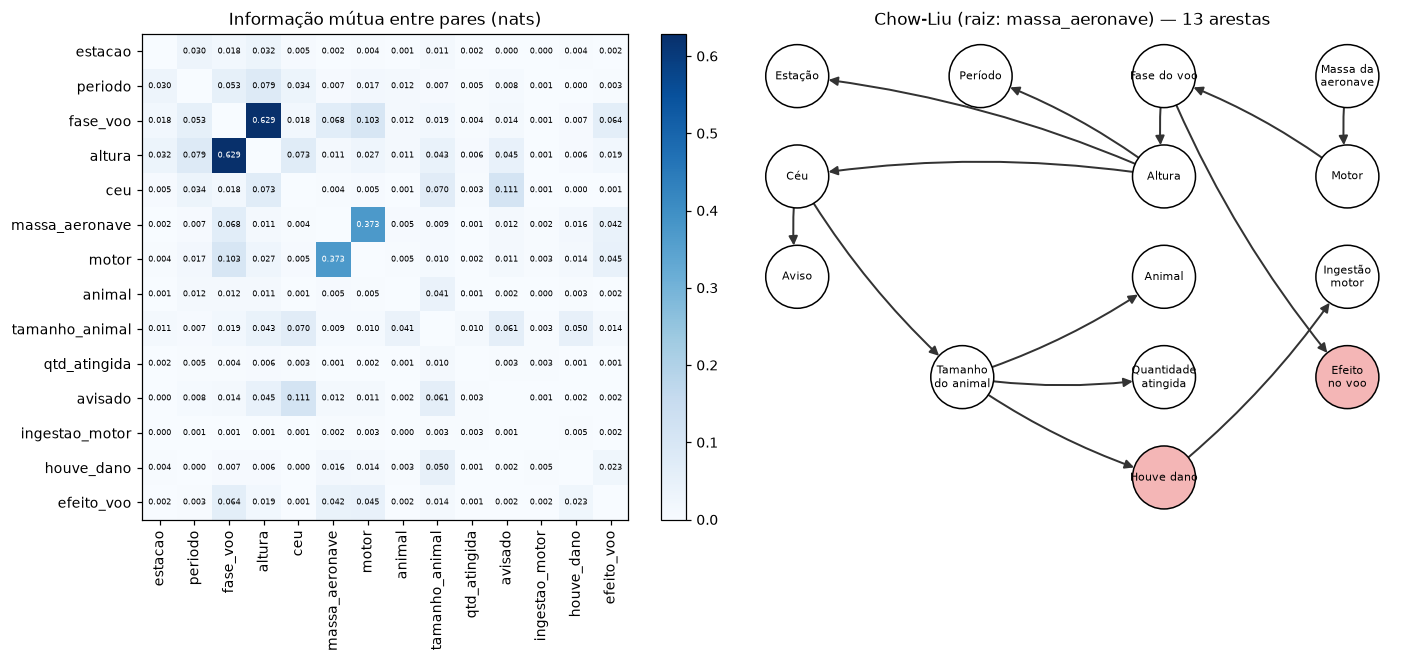

In [13]:
from pgmpy.estimators import TreeSearch

info_mutua = pd.DataFrame(0.0, index=NOS, columns=NOS)
for a, b in product(NOS, NOS):
    if a < b:
        info_mutua.loc[a, b] = info_mutua.loc[b, a] = mutual_info_score(dados[a], dados[b])

# O Chow-Liu é calculado uma vez: a árvore geradora máxima não depende da raiz. O pgmpy orienta a árvore com uma
# busca em largura a partir da raiz (nx.bfs_tree), e repetimos essa orientação para cada raiz candidata.
# n_jobs=1: o padrão (-1) abre um processo por núcleo e multiplica o uso de memória.
t0 = time.time()
arvore = TreeSearch(dados, root_node=NOS[0], n_jobs=1).estimate(estimator_type="chow-liu", show_progress=False)
arvore_nao_orientada = nx.Graph(arvore.edges())
print(f"Chow-Liu: {time.time() - t0:.1f} s")

def orientar(raiz):
    g = DAG(nx.bfs_tree(arvore_nao_orientada, raiz).edges())
    g.add_nodes_from(NOS)
    return g

assert set(orientar(NOS[0]).edges()) == set(arvore.edges())
arvores = {r: orientar(r) for r in NOS}
concordancia = {r: len(set(g.edges()) & set(ARESTAS_ELICITADAS)) for r, g in arvores.items()}
raiz = max(NOS, key=lambda r: concordancia[r])
dag_cl = arvores[raiz]
bics_raizes = {r: round(bic(X=dados, causal_graph=g), 3) for r, g in arvores.items()}
assert len(set(bics_raizes.values())) == 1, "raízes diferentes deveriam dar o mesmo BIC"
assert len(dag_cl.edges()) == 13 and max(d for _, d in dag_cl.in_degree()) <= 1
print(f"Raiz escolhida: {raiz} ({concordancia[raiz]} arestas com a orientação da elicitada); "
      f"BIC idêntico para as 14 raízes: {next(iter(bics_raizes.values())):,.1f}")
print("Arestas:", sorted(dag_cl.edges()))

fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1]})
im = axs[0].imshow(info_mutua.values, cmap="Blues")
axs[0].set_xticks(range(len(NOS)), NOS, rotation=90)
axs[0].set_yticks(range(len(NOS)), NOS)
for (i, j), v in np.ndenumerate(info_mutua.values):
    if i != j:
        axs[0].text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=5.5,
                    color="white" if v > info_mutua.values.max() / 2 else "black")
axs[0].set_title("Informação mútua entre pares (nats)")
fig.colorbar(im, ax=axs[0], fraction=0.046)
desenhar(dag_cl, axs[1], f"Chow-Liu (raiz: {raiz}) — 13 arestas")
fig.tight_layout()
salvar_fig(fig, "fig_rede_chowliu")
plt.show()

### 4.4 Comparação com a estrutura elicitada

Comparar as setas uma a uma pode enganar. Grafos diferentes podem representar exatamente as mesmas independências
condicionais (dizemos que estão na mesma classe de equivalência de Markov), e o BIC dá a mesma nota para todos eles. Na
cadeia $A \to B \to C$, por exemplo, inverter as duas setas não muda nada para o score. A orientação de uma aresta só
vem dos dados quando é forçada por alguma v-estrutura, como $A \to B \leftarrow C$, que nenhum grafo equivalente pode
desfazer. Chamamos essas arestas de *compelidas*, e as outras de *reversíveis*. O grafo que representa a classe
inteira, com as arestas reversíveis sem orientação, é o CPDAG.

Fazemos então duas comparações. A primeira é aresta por aresta, como os grafos foram desenhados. A segunda é entre os
CPDAGs, com a distância de Hamming estrutural (SHD), que conta os pares de variáveis cuja ligação (sem aresta, `→`,
`←` ou sem orientação) muda de um grafo para o outro.

In [14]:
def estado_par(pdag, a, b):
    if (a, b) in pdag.directed_edges:
        return "→"
    if (b, a) in pdag.directed_edges:
        return "←"
    if (a, b) in pdag.undirected_edges or (b, a) in pdag.undirected_edges:
        return "—"
    return None

def shd_cpdag(g1, g2):
    p1, p2 = g1.to_pdag(), g2.to_pdag()
    return sum(estado_par(p1, a, b) != estado_par(p2, a, b) for i, a in enumerate(NOS) for b in NOS[i + 1:])

def situacao(aresta, g):
    a, b = aresta
    if g.has_edge(a, b):
        return "igual"
    if g.has_edge(b, a):
        reversivel = estado_par(g.to_pdag(), a, b) == "—"
        return "invertida (reversível)" if reversivel else "invertida (compelida)"
    return "ausente"

ESTRUTURAS = {"Elicitada": dag_elic, "HC livre": dag_hc, "HC por camadas": dag_cam, "Chow-Liu": dag_cl}
tab_metricas = pd.DataFrame([{
    "Estrutura": nome, "Arestas": len(g.edges()), "Parâmetros livres": n_parametros(g),
    "BIC": round(bic(X=dados, causal_graph=g), 1),
    "SHD vs elicitada": shd_cpdag(dag_elic, g), "SHD vs HC livre": shd_cpdag(dag_hc, g)}
    for nome, g in ESTRUTURAS.items()])
salvar_tab(tab_metricas, "tab_metricas_estruturas")
display(tab_metricas)

linhas = [{"Aresta elicitada": f"{a} → {b}", "HC livre": situacao((a, b), dag_hc),
           "HC por camadas": situacao((a, b), dag_cam), "Chow-Liu": situacao((a, b), dag_cl),
           "IM (nats)": round(info_mutua.loc[a, b], 4)}
          for a, b in ARESTAS_ELICITADAS]
tab_arestas = pd.DataFrame(linhas)
salvar_tab(tab_arestas, "tab_comparacao_arestas")
display(tab_arestas)

def so_aprendidas(g):
    return pd.DataFrame([{"Aresta": f"{a} → {b}", "No CPDAG": estado_par(g.to_pdag(), a, b),
                          "IM (nats)": round(info_mutua.loc[a, b], 4)}
                         for a, b in sorted(g.edges())
                         if not dag_elic.has_edge(a, b) and not dag_elic.has_edge(b, a)])
tab_so_hc, tab_so_cam, tab_so_cl = so_aprendidas(dag_hc), so_aprendidas(dag_cam), so_aprendidas(dag_cl)
salvar_tab(tab_so_hc, "tab_arestas_so_hc")
salvar_tab(tab_so_cam, "tab_arestas_so_hc_camadas")
salvar_tab(tab_so_cl, "tab_arestas_so_cl")
print("Arestas só no HC livre:")
display(tab_so_hc)
print("Arestas só no HC por camadas:")
display(tab_so_cam)
print("Arestas só no Chow-Liu:")
display(tab_so_cl)

,Estrutura,Arestas,Parâmetros livres,BIC,SHD vs elicitada,SHD vs HC livre
0,Elicitada,17,377,-736568.5,0,28
1,HC livre,31,1302,-696115.1,28,0
2,HC por camadas,31,1345,-697125.0,25,13
3,Chow-Liu,13,180,-709953.5,21,25


,Aresta elicitada,HC livre,HC por camadas,Chow-Liu,IM (nats)
0,estacao → ceu,ausente,invertida (reversível),ausente,0.0051
1,ceu → avisado,igual,igual,igual,0.1114
2,estacao → animal,ausente,ausente,ausente,0.0012
3,periodo → animal,igual,igual,ausente,0.0122
4,fase_voo → altura,invertida (reversível),invertida (reversível),igual,0.6286
5,altura → animal,igual,igual,ausente,0.0112
6,animal → tamanho_animal,invertida (compelida),invertida (compelida),invertida (reversível),0.0406
7,animal → qtd_atingida,ausente,ausente,ausente,0.0009
8,tamanho_animal → houve_dano,igual,igual,igual,0.0501
9,qtd_atingida → houve_dano,invertida (compelida),ausente,ausente,0.0014


Arestas só no HC livre:


,Aresta,No CPDAG,IM (nats)
0,altura → avisado,→,0.0446
1,altura → ceu,—,0.0727
2,altura → estacao,—,0.0323
3,altura → houve_dano,→,0.0061
4,altura → periodo,—,0.0787
5,altura → tamanho_animal,→,0.0435
6,avisado → tamanho_animal,→,0.0613
7,ceu → tamanho_animal,→,0.0700
8,fase_voo → efeito_voo,→,0.0637
9,fase_voo → periodo,—,0.0535


Arestas só no HC por camadas:


,Aresta,No CPDAG,IM (nats)
0,altura → avisado,—,0.0446
1,altura → massa_aeronave,—,0.0108
2,altura → motor,—,0.0274
3,altura → tamanho_animal,—,0.0435
4,avisado → massa_aeronave,—,0.0120
5,avisado → tamanho_animal,—,0.0613
6,ceu → altura,—,0.0727
7,ceu → periodo,—,0.0336
8,ceu → tamanho_animal,—,0.0700
9,estacao → altura,—,0.0323


Arestas só no Chow-Liu:


,Aresta,No CPDAG,IM (nats)
0,altura → ceu,—,0.0727
1,altura → estacao,—,0.0323
2,altura → periodo,—,0.0787
3,ceu → tamanho_animal,—,0.0700
4,fase_voo → efeito_voo,—,0.0637
5,motor → fase_voo,—,0.1027
6,tamanho_animal → qtd_atingida,—,0.0104


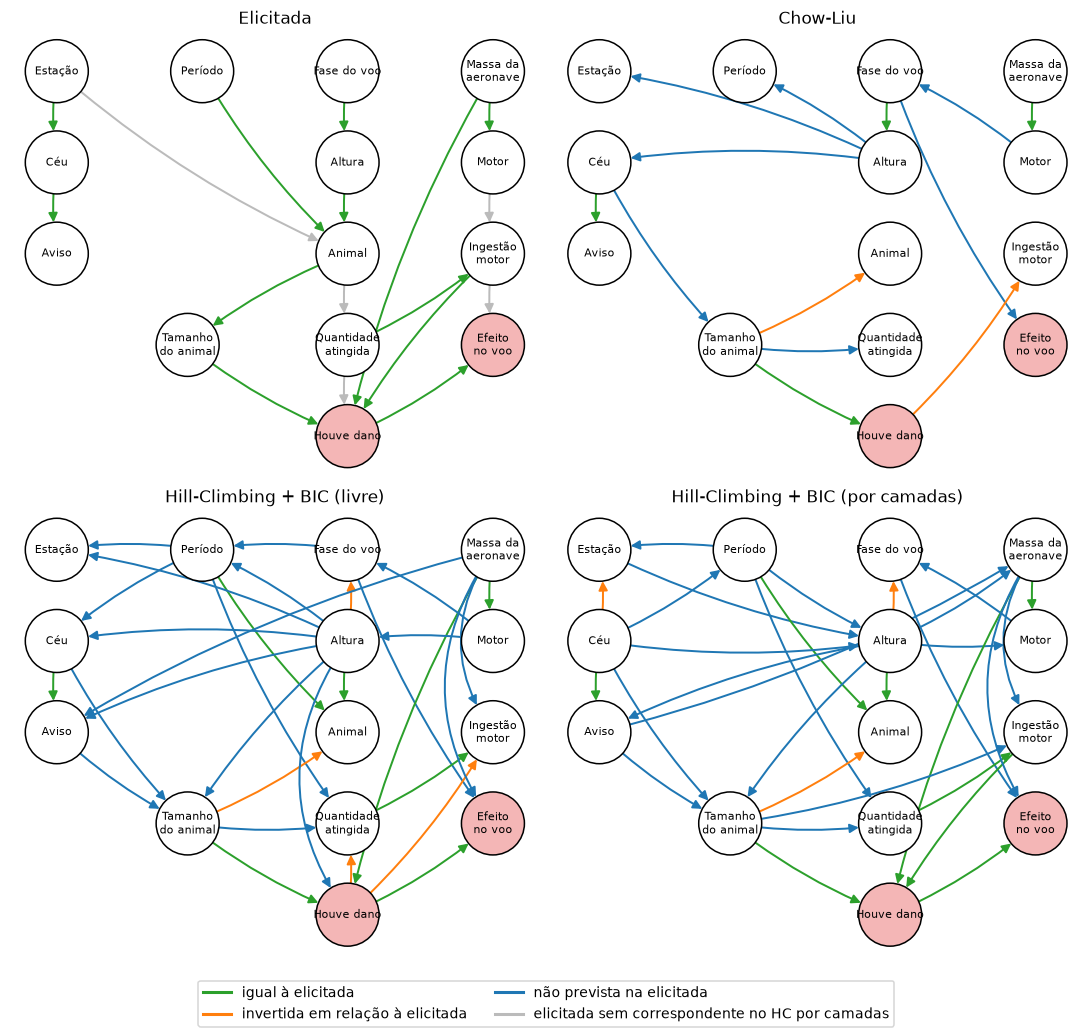

In [15]:
CORES = {"igual": "#2CA02C", "invertida": "#FF7F0E", "nova": "#1F77B4", "ausente": "#BBBBBB"}

def cores_comparacao(g):
    cores = {}
    for a, b in g.edges():
        if dag_elic.has_edge(a, b):
            cores[(a, b)] = CORES["igual"]
        elif dag_elic.has_edge(b, a):
            cores[(a, b)] = CORES["invertida"]
        else:
            cores[(a, b)] = CORES["nova"]
    return cores

fig, axs = plt.subplots(2, 2, figsize=(10, 9.4))
desenhar(dag_elic, axs[0, 0], "Elicitada",
         {e: (CORES["igual"] if (dag_cam.has_edge(*e) or dag_cam.has_edge(*e[::-1])) else CORES["ausente"])
          for e in dag_elic.edges()})
desenhar(dag_cl, axs[0, 1], "Chow-Liu", cores_comparacao(dag_cl))
desenhar(dag_hc, axs[1, 0], "Hill-Climbing + BIC (livre)", cores_comparacao(dag_hc))
desenhar(dag_cam, axs[1, 1], "Hill-Climbing + BIC (por camadas)", cores_comparacao(dag_cam))
from matplotlib.lines import Line2D
fig.legend([Line2D([], [], color=c, lw=2) for c in CORES.values()],
           ["igual à elicitada", "invertida em relação à elicitada", "não prevista na elicitada",
            "elicitada sem correspondente no HC por camadas"], loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.06, 1, 1))
salvar_fig(fig, "fig_comparacao")
plt.show()

In [16]:
# Os estados "desconhecido" aparecem juntos? Se sim, parte das dependências vem da forma do relato, não do fenômeno.
com_desc = [c for c in NOS if "desconhecido" in STATE_NAMES[c]]
desc = pd.DataFrame({c: (df[c] == "desconhecido") for c in com_desc})
coocorrencia = pd.DataFrame(
    [[desc.loc[desc[a], b].mean() / desc[b].mean() if a != b else np.nan for b in com_desc] for a in com_desc],
    index=com_desc, columns=com_desc).round(2)
print("Razão P(B desconhecido | A desconhecido) / P(B desconhecido)  (1 = independentes):")
display(coocorrencia)

Razão P(B desconhecido | A desconhecido) / P(B desconhecido)  (1 = independentes):


,periodo,altura,ceu,massa_aeronave,motor,tamanho_animal,avisado
periodo,NaN,1.43,2.48,1.55,1.63,1.42,1.32
altura,1.43,NaN,2.21,1.35,1.35,1.73,1.40
ceu,2.48,2.21,NaN,1.37,1.33,2.23,1.77
massa_aeronave,1.55,1.35,1.37,NaN,114.14,1.16,1.33
motor,1.63,1.35,1.33,114.14,NaN,1.04,1.27
tamanho_animal,1.42,1.73,2.23,1.16,1.04,NaN,1.58
avisado,1.32,1.40,1.77,1.33,1.27,1.58,NaN


**Discussão.** O Hill-Climbing livre chegou a 31 arestas e BIC de −696.115, e o por camadas, também a 31 arestas, a
−697.125. A ordem custou 1.010 pontos de BIC, menos de 0,2% do score, para proibir seis setas que o algoritmo livre tinha
escolhido, entre elas `houve_dano → ingestao_motor` e `houve_dano → qtd_atingida`. A rede elicitada, com 17 arestas,
fica em −736.569, e a árvore de Chow-Liu, com apenas 13, em −709.954. Uma árvore com BIC 26 mil pontos melhor que o
nosso desenho mostra que deixamos de fora dependências fortes. A matriz de informação mútua aponta quais:
`motor`–`fase_voo` (0,103), `altura`–`periodo` (0,079), `ceu`–`altura` (0,073), `ceu`–`tamanho_animal` (0,070) e
`fase_voo`–`efeito_voo` (0,064) são mais fortes que quase todas as arestas que desenhamos. As 13 arestas da árvore
aparecem, com alguma orientação, nas duas versões do Hill-Climbing: as ligações mais informativas formam a base das
redes aprendidas.

Na rede por camadas, nove das 17 arestas que desenhamos aparecem exatamente como previmos: `ceu → avisado`,
`periodo → animal`, `altura → animal`, `tamanho_animal → houve_dano`, `qtd_atingida → ingestao_motor`,
`massa_aeronave → motor`, `massa_aeronave → houve_dano`, `ingestao_motor → houve_dano` e `houve_dano → efeito_voo`. O
Hill-Climbing livre acerta oito delas, mas inverte `ingestao_motor → houve_dano` e `qtd_atingida → houve_dano`, como se
o dano causasse a ingestão e a quantidade de animais atingidos. As duas inversões são compelidas, isto é, os dados
preferem essa direção, embora ela não tenha sentido físico. Acontece que o BIC não procura causas, e sim a forma mais
compacta de escrever a distribuição conjunta. A ordem por camadas corrige isso sem abandonar o score.

Cinco arestas que desenhamos não aparecem na rede por camadas: `estacao → animal`, `animal → qtd_atingida`,
`qtd_atingida → houve_dano`, `motor → ingestao_motor` e `ingestao_motor → efeito_voo`. Todas têm informação mútua muito
baixa, entre 0,0009 e 0,0027 nats. O BIC cobra $\frac{1}{2}\log n \approx 5{,}6$ pontos por parâmetro, e uma aresta
que chega a um nó que já tem vários pais multiplica o número de parâmetros desse nó. O caso de
`ingestao_motor → efeito_voo` ilustra bem isso. Acrescentá-la à rede por camadas aumenta a log-verossimilhança em 156,
mas cria 192 parâmetros novos, e o BIC piora 919. Como só 3% das colisões têm ingestão, um efeito grande nesses casos
pesa pouco na verossimilhança da base inteira. A falta dessa aresta reaparece na Tarefa 4.

Três arestas aparecem com a direção trocada. Em `estacao`–`ceu` e `fase_voo`–`altura` a troca é reversível, ou seja,
os dados não distinguem as duas direções. Só `animal → tamanho_animal` virou `tamanho_animal → animal` de forma
compelida. As duas variáveis estão na mesma camada, então a ordem não impede essa escolha, e ela também tem uma
leitura razoável: saber que o animal é grande já diz muito sobre ele ser um mamífero terrestre.

Sobram as 19 arestas que só o Hill-Climbing por camadas encontrou. Nove delas ligam entre si `avisado`, `ceu`, `altura`,
`periodo`, `estacao` e `tamanho_animal`, e quatro dessas variáveis têm entre 22% e 51% de valores `desconhecido`. A
tabela de coocorrência explica parte disso: quando o céu é `desconhecido`, a chance de o período também ser é 2,5
vezes maior que a média, e a maioria dos pares fica com razões entre 1,3 e 2,5. Quem deixa um campo do relato em branco
costuma deixar outros também, e, como o faltante virou um estado, a rede aprende essas dependências. Outras arestas
novas são legítimas e só não tínhamos pensado nelas, como `motor → fase_voo` (helicópteros e aviões a pistão voam de
um jeito diferente dos jatos) e `fase_voo → efeito_voo` (uma decolagem abortada só pode acontecer na corrida de
decolagem, e de fato todos os 800 casos estão nessa fase).

## 5. Tarefa 4 — Estimação dos parâmetros e inferência

### 5.1 Máxima verossimilhança × estimação bayesiana

Com a estrutura do Hill-Climbing por camadas fixada, falta estimar a tabela $P(X_i \mid \mathrm{Pa}(X_i))$ de cada nó. A forma
mais direta é a máxima verossimilhança (MLE), $\hat\theta_{ijk} = N_{ijk}/N_{ij}$, que é simplesmente a frequência de
cada estado em cada combinação de valores dos pais. O problema está nas combinações raras: com poucos registros a
estimativa oscila muito, e uma combinação que nunca apareceu nos dados recebe probabilidade zero.

A estimação bayesiana com prior BDeu contorna isso somando pseudo-contagens iguais para todos os estados antes de
calcular as frequências:

$$\hat\theta_{ijk} = \frac{N_{ijk} + \alpha/(q_i r_i)}{N_{ij} + \alpha/q_i},$$

em que $r_i$ é o número de estados do nó, $q_i$ é o número de combinações dos pais e $\alpha$ é o *tamanho amostral
equivalente* (ESS), que diz quanto peso o prior tem. A base tem vários estados raros, como `solo_taxi`,
`desligamento_motor` e `qtd_atingida = desconhecido`. Para escolher o estimador e o valor de $\alpha$, ajustamos cada
um com 80% dos dados e medimos a log-verossimilhança média nos 20% restantes.

In [17]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE

def ajustar(g, base, estimador):
    m = DiscreteBayesianNetwork(g.edges())
    m.add_nodes_from(NOS)
    m.fit(base, estimator=estimador)
    assert m.check_model()
    return m

def log_verossimilhanca(m, base):
    total = np.zeros(len(base))
    for cpd in m.get_cpds():
        indices = tuple(base[v].astype(str).map({s: i for i, s in enumerate(cpd.state_names[v])}).to_numpy()
                        for v in cpd.variables)
        with np.errstate(divide="ignore"):
            total += np.log(cpd.values[indices])
    return total

treino = dados.sample(frac=0.8, random_state=SEED)
teste = dados.drop(treino.index)
CANDIDATOS = {"MLE": lambda: DiscreteMLE(state_names=STATE_NAMES)}
for alfa in (1, 5, 10, 50, 100):
    CANDIDATOS[f"BDeu, α = {alfa}"] = lambda alfa=alfa: DiscreteBayesianEstimator(
        state_names=STATE_NAMES, prior_type="BDeu", equivalent_sample_size=alfa)

resultados = []
for nome, fabrica in CANDIDATOS.items():
    ll = log_verossimilhanca(ajustar(dag_cam, treino, fabrica()), teste)
    finitos = np.isfinite(ll)
    resultados.append({"Estimador": nome, "Registros com P = 0": int((~finitos).sum()),
                       "LL média no teste": round(ll.mean(), 4) if finitos.all() else -np.inf,
                       "LL média (só P > 0)": round(ll[finitos].mean(), 4)})
tab_estimadores = pd.DataFrame(resultados)
salvar_tab(tab_estimadores, "tab_estimadores")
display(tab_estimadores)
melhor = tab_estimadores.loc[tab_estimadores["LL média no teste"].idxmax(), "Estimador"]
print("Escolhido:", melhor)

,Estimador,Registros com P = 0,LL média no teste,LL média (só P > 0)
0,MLE,15,-inf,-9.5157
1,"BDeu, α = 1",0,-9.5299,-9.5299
2,"BDeu, α = 5",0,-9.5284,-9.5284
3,"BDeu, α = 10",0,-9.5278,-9.5278
4,"BDeu, α = 50",0,-9.5273,-9.5273
5,"BDeu, α = 100",0,-9.5281,-9.5281


Escolhido: BDeu, α = 50


In [18]:
modelo = ajustar(dag_cam, dados, CANDIDATOS[melhor]())
print("Modelo válido:", modelo.check_model(), "| CPDs:", len(modelo.get_cpds()))
for no in ("houve_dano", "efeito_voo"):
    cpd = modelo.get_cpds(no)
    print(f"\nP({no} | {', '.join(cpd.variables[1:]) or '—'})  —  {cpd.values.size} entradas")

def cpd_como_tabela(no):
    # Uma linha por configuração dos pais, uma coluna por estado do nó (em %).
    cpd = modelo.get_cpds(no)
    pais = cpd.variables[1:]
    valores = cpd.values.reshape(len(cpd.state_names[no]), -1).T
    configuracoes = list(product(*[cpd.state_names[p] for p in pais])) or [()]
    tabela = pd.DataFrame(100 * valores, columns=[f"{no}={e} (%)" for e in cpd.state_names[no]]).round(2)
    for k, p in enumerate(pais):
        tabela.insert(k, p, [c[k] for c in configuracoes])
    return tabela

tab_cpd_dano = cpd_como_tabela("houve_dano")
salvar_tab(tab_cpd_dano, "tab_cpd_houve_dano")
display(tab_cpd_dano)
tab_cpd_efeito = cpd_como_tabela("efeito_voo")
print("P(efeito_voo | pais) — configurações com houve_dano = sim:")
display(tab_cpd_efeito[tab_cpd_efeito["houve_dano"] == "sim"])

Modelo válido: True | CPDs: 14

P(houve_dano | ingestao_motor, massa_aeronave, tamanho_animal)  —  64 entradas

P(efeito_voo | fase_voo, houve_dano, massa_aeronave)  —  240 entradas


,ingestao_motor,massa_aeronave,tamanho_animal,houve_dano=nao (%),houve_dano=sim (%)
0,nao,leve,pequeno,93.55,6.45
1,nao,leve,medio,63.88,36.12
2,nao,leve,grande,38.01,61.99
3,nao,leve,desconhecido,86.78,13.22
4,nao,media,pequeno,96.76,3.24
5,nao,media,medio,80.87,19.13
6,nao,media,grande,59.29,40.71
7,nao,media,desconhecido,93.99,6.01
8,nao,pesada,pequeno,98.05,1.95
9,nao,pesada,medio,88.24,11.76


P(efeito_voo | pais) — configurações com houve_dano = sim:


,fase_voo,houve_dano,massa_aeronave,efeito_voo=nenhum (%),efeito_voo=pouso_precaucao (%),efeito_voo=decolagem_abortada (%),efeito_voo=desligamento_motor (%),efeito_voo=outro (%)
4,solo_taxi,sim,leve,53.10,3.45,3.45,20.00,20.00
5,solo_taxi,sim,media,20.00,20.00,20.00,20.00,20.00
6,solo_taxi,sim,pesada,59.18,10.20,10.20,10.20,10.20
7,solo_taxi,sim,desconhecido,20.00,20.00,20.00,20.00,20.00
12,corrida_decolagem,sim,leve,25.69,19.85,51.23,1.61,1.61
13,corrida_decolagem,sim,media,44.99,34.47,17.37,1.59,1.59
14,corrida_decolagem,sim,pesada,54.03,29.03,12.27,1.76,2.90
15,corrida_decolagem,sim,desconhecido,54.64,29.90,5.15,5.15,5.15
20,subida,sim,leve,39.37,57.33,0.05,1.02,2.23
21,subida,sim,media,48.74,48.74,0.11,1.75,0.66


### 5.2 Inferência: respostas às perguntas da Tarefa 1

As consultas usam eliminação de variáveis, que calcula as probabilidades de forma exata. Ao lado de cada resposta,
mostramos a frequência observada nos registros que têm a mesma evidência (coluna *Empírico*, com o número de registros
de suporte). Quando há muitos registros, as duas devem coincidir. Quando há poucos, a rede completa a informação com o
que aprendeu de situações parecidas, e as duas podem se afastar.

,Perfil,Evidência,Rede (%),Empírico (%),Suporte
0,sem evidência,(nenhuma),7.4,7.7,72812
1,animal grande,tamanho_animal=grande,39.2,44.0,4259
2,"leve, pistão, animal terrestre","massa_aeronave=leve, motor=pistao, animal=terr...",59.5,69.4,235
3,"pesada, jato, ave pequena, aproximação","massa_aeronave=pesada, motor=jato, animal=ave,...",2.2,2.1,15548
4,"leve, pistão, animal grande, em rota","massa_aeronave=leve, motor=pistao, tamanho_ani...",62.3,81.7,115


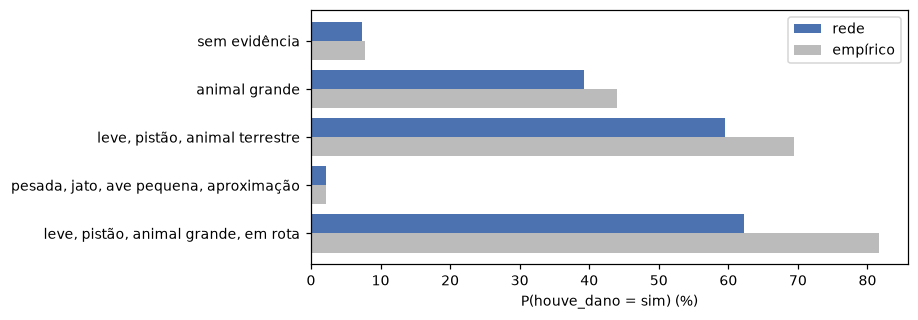

In [19]:
from pgmpy.inference import CausalInference, VariableElimination

inferencia = VariableElimination(modelo)
causal = CausalInference(modelo)

def consultar(alvo, estado, evidencia):
    p = inferencia.query([alvo], evidence=evidencia, show_progress=False).get_value(**{alvo: estado})
    mascara = np.ones(len(df), dtype=bool)
    for v, s in evidencia.items():
        mascara &= (df[v] == s).to_numpy()
    n = int(mascara.sum())
    empirico = (df.loc[mascara, alvo] == estado).mean() if n else np.nan
    return {"Evidência": ", ".join(f"{v}={s}" for v, s in evidencia.items()) or "(nenhuma)",
            "Rede (%)": round(100 * p, 1), "Empírico (%)": round(100 * empirico, 1), "Suporte": n}

PERFIS_Q1 = {
    "sem evidência": {},
    "animal grande": {"tamanho_animal": "grande"},
    "leve, pistão, animal terrestre": {"massa_aeronave": "leve", "motor": "pistao", "animal": "terrestre"},
    "pesada, jato, ave pequena, aproximação": {"massa_aeronave": "pesada", "motor": "jato", "animal": "ave",
                                               "tamanho_animal": "pequeno", "fase_voo": "aproximacao"},
    "leve, pistão, animal grande, em rota": {"massa_aeronave": "leve", "motor": "pistao",
                                             "tamanho_animal": "grande", "fase_voo": "rota"},
}
tab_q1 = pd.DataFrame([{"Perfil": nome, **consultar("houve_dano", "sim", ev)} for nome, ev in PERFIS_Q1.items()])
salvar_tab(tab_q1, "tab_q1")
display(tab_q1)

fig, ax = plt.subplots(figsize=(7, 3))
y = np.arange(len(tab_q1))
ax.barh(y - 0.2, tab_q1["Rede (%)"], 0.4, label="rede", color="#4C72B0")
ax.barh(y + 0.2, tab_q1["Empírico (%)"], 0.4, label="empírico", color="#BBBBBB")
ax.set_yticks(y, tab_q1["Perfil"]); ax.invert_yaxis()
ax.set_xlabel("P(houve_dano = sim) (%)"); ax.legend()
salvar_fig(fig, "fig_q1")
plt.show()

In [20]:
# Q2 — efeito no voo dado ingestão pelo motor
def distribuicao(alvo, evidencia, do=None):
    # Intervenção por "cirurgia" do grafo: modelo.do() remove as arestas que entram nas variáveis intervindas,
    # e P(alvo | do(X=x), e) = P_mutilado(alvo | X=x, e).
    if do:
        f = VariableElimination(modelo.do(list(do))).query([alvo], evidence={**evidencia, **do}, show_progress=False)
    else:
        f = inferencia.query([alvo], evidence=evidencia, show_progress=False)
    return pd.Series({s: f.get_value(**{alvo: s}) for s in STATE_NAMES[alvo]})

CENARIOS_Q2 = {"sem ingestão": {"ingestao_motor": "nao"}, "com ingestão": {"ingestao_motor": "sim"},
               "com ingestão, dois ou mais animais": {"ingestao_motor": "sim", "qtd_atingida": "dois_ou_mais"}}
linhas = []
for nome, ev in CENARIOS_Q2.items():
    rede = distribuicao("efeito_voo", ev)
    mascara = np.logical_and.reduce([(df[v] == s).to_numpy() for v, s in ev.items()])
    emp = df.loc[mascara, "efeito_voo"].value_counts(normalize=True).reindex(STATE_NAMES["efeito_voo"]).fillna(0)
    linhas.append({"Cenário": nome, "Suporte": int(mascara.sum()),
                   **{f"{s} (%)": f"{100 * rede[s]:.1f} ({100 * emp[s]:.1f})".replace(".", ",") for s in STATE_NAMES["efeito_voo"]}})
tab_q2 = pd.DataFrame(linhas)
salvar_tab(tab_q2, "tab_q2")
print("P(efeito_voo | evidência) — rede (empírico)")
display(tab_q2)

P(efeito_voo | evidência) — rede (empírico)


,Cenário,Suporte,nenhum (%),pouso_precaucao (%),decolagem_abortada (%),desligamento_motor (%),outro (%)
0,sem ingestão,70572,"93,7 (93,7)","4,5 (4,6)","1,1 (1,1)","0,2 (0,1)","0,6 (0,6)"
1,com ingestão,2240,"93,5 (84,9)","4,5 (10,8)","1,0 (2,0)","0,3 (1,2)","0,9 (1,1)"
2,"com ingestão, dois ou mais animais",612,"93,3 (82,4)","4,5 (13,2)","1,1 (2,3)","0,3 (1,0)","0,8 (1,1)"


**Variante com a aresta `ingestao_motor → efeito_voo`.** A rede por camadas quase não muda o efeito no voo quando há
ingestão, enquanto nos dados a chance de algum efeito mais que dobra. A aresta que faria essa ligação direta estava na
nossa rede elicitada, mas o BIC a descartou. Para medir o que se ganha e o que se perde com ela, repetimos a busca por
camadas obrigando essa aresta (`required_edges`) e comparamos as duas redes pelo BIC, pela log-verossimilhança no
conjunto de teste e pelas respostas da Q2 e da Q3.

In [21]:
# Variante: a mesma busca por camadas, obrigando a aresta ingestao_motor → efeito_voo, que o BIC descartou.
dag_var = hc_camadas(obrigatorias=[("ingestao_motor", "efeito_voo")])
print("Arestas que entram:", sorted(set(dag_var.edges()) - set(dag_cam.edges())),
      "| arestas que saem:", sorted(set(dag_cam.edges()) - set(dag_var.edges())))
modelo_var = ajustar(dag_var, dados, CANDIDATOS[melhor]())
inferencia_var = VariableElimination(modelo_var)

def prob(inf, alvo, estado, evidencia):
    return 100 * inf.query([alvo], evidence=evidencia, show_progress=False).get_value(**{alvo: estado})

def fmt(x, casas=1):
    return _br(f"{x:,.{casas}f}")

com_ingestao, desligou = df["ingestao_motor"] == "sim", df["efeito_voo"] == "desligamento_motor"
linhas = []
for nome, g, inf in (("HC por camadas", dag_cam, inferencia), ("camadas + ingestao_motor → efeito_voo", dag_var, inferencia_var)):
    linhas.append({
        "Estrutura": nome, "BIC": fmt(bic(X=dados, causal_graph=g)),
        "LL média no teste": fmt(log_verossimilhanca(ajustar(g, treino, CANDIDATOS[melhor]()), teste).mean(), 4),
        "P(algum efeito | ingestão) (%)": fmt(100 - prob(inf, "efeito_voo", "nenhum", {"ingestao_motor": "sim"})),
        "P(grande | desligamento) (%)": fmt(prob(inf, "tamanho_animal", "grande", {"efeito_voo": "desligamento_motor"}))})
linhas.append({"Estrutura": "dados (empírico)", "BIC": "—", "LL média no teste": "—",
               "P(algum efeito | ingestão) (%)": fmt(100 * (df.loc[com_ingestao, "efeito_voo"] != "nenhum").mean()),
               "P(grande | desligamento) (%)": fmt(100 * (df.loc[desligou, "tamanho_animal"] == "grande").mean())})
tab_variante = pd.DataFrame(linhas)
salvar_tab(tab_variante, "tab_variante_q2")
display(tab_variante)

Arestas que entram: [('ingestao_motor', 'efeito_voo')] | arestas que saem: [('houve_dano', 'efeito_voo')]


,Estrutura,BIC,LL média no teste,P(algum efeito | ingestão) (%),P(grande | desligamento) (%)
0,HC por camadas,"-697.125,0","-9,5273","6,5","19,5"
1,camadas + ingestao_motor → efeito_voo,"-697.901,9","-9,5372","14,4","7,5"
2,dados (empírico),—,—,"15,1","38,2"


In [22]:
# Q3 — diagnóstico: o que atingiu a aeronave quando o motor foi desligado?
linhas = []
for alvo in ("tamanho_animal", "qtd_atingida"):
    for cond in ("nenhum", "desligamento_motor"):
        rede = distribuicao(alvo, {"efeito_voo": cond})
        emp = df.loc[df["efeito_voo"] == cond, alvo].value_counts(normalize=True).reindex(STATE_NAMES[alvo]).fillna(0)
        for s in STATE_NAMES[alvo]:
            linhas.append({"Variável": alvo, "Estado": s, "efeito_voo": cond,
                           "Rede (%)": round(100 * rede[s], 1), "Empírico (%)": round(100 * emp[s], 1)})
tab_q3 = (pd.DataFrame(linhas).pivot_table(index=["Variável", "Estado"], columns="efeito_voo",
                                           values=["Rede (%)", "Empírico (%)"], sort=False))
tab_q3.columns = [f"{m} | {e}" for m, e in tab_q3.columns]
tab_q3 = tab_q3.reset_index()
salvar_tab(tab_q3, "tab_q3")
print(f"Suporte: efeito_voo=desligamento_motor em {int((df['efeito_voo'] == 'desligamento_motor').sum())} registros")
display(tab_q3)

Suporte: efeito_voo=desligamento_motor em 110 registros


,Variável,Estado,Rede (%) | nenhum,Rede (%) | desligamento_motor,Empírico (%) | nenhum,Empírico (%) | desligamento_motor
0,tamanho_animal,pequeno,58.5,42.5,59.5,30.0
1,tamanho_animal,medio,11.6,20.0,11.1,27.3
2,tamanho_animal,grande,5.5,19.5,4.8,38.2
3,tamanho_animal,desconhecido,24.3,18.0,24.6,4.5
4,qtd_atingida,um,89.2,88.1,89.6,80.9
5,qtd_atingida,dois_ou_mais,10.8,11.9,10.4,19.1


In [23]:
# Q4 — intervenção: e se o manejo de fauna afastasse os animais grandes?
def empirico_dano(mascara):
    return round(100 * (df.loc[mascara, "houve_dano"] == "sim").mean(), 2)

linhas = [{"Consulta": "P(dano)", "Rede (%)": round(100 * distribuicao("houve_dano", {})["sim"], 2),
           "Empírico (%)": empirico_dano(np.ones(len(df), dtype=bool))}]
for s in ("pequeno", "grande"):
    linhas.append({"Consulta": f"P(dano | tamanho_animal={s})",
                   "Rede (%)": round(100 * distribuicao("houve_dano", {"tamanho_animal": s})["sim"], 2),
                   "Empírico (%)": empirico_dano(df["tamanho_animal"] == s)})
    linhas.append({"Consulta": f"P(dano | do(tamanho_animal={s}))",
                   "Rede (%)": round(100 * distribuicao("houve_dano", {}, do={"tamanho_animal": s})["sim"], 2),
                   "Empírico (%)": np.nan})
# Conferência com o módulo de inferência causal do pgmpy (aceita a consulta porque houve_dano descende de tamanho_animal).
for s in ("pequeno", "grande"):
    f = causal.query(["houve_dano"], do={"tamanho_animal": s}, show_progress=False)
    assert abs(f.get_value(houve_dano="sim") - distribuicao("houve_dano", {}, do={"tamanho_animal": s})["sim"]) < 1e-9
tab_q4 = pd.DataFrame(linhas)
salvar_tab(tab_q4, "tab_q4")
print("Pais de tamanho_animal (arestas cortadas pela intervenção):", sorted(modelo.predecessors("tamanho_animal")))
print("Caminhos dirigidos de tamanho_animal até houve_dano:", list(nx.all_simple_paths(modelo, "tamanho_animal", "houve_dano")))
display(tab_q4)

Pais de tamanho_animal (arestas cortadas pela intervenção): ['altura', 'avisado', 'ceu']
Caminhos dirigidos de tamanho_animal até houve_dano: [['tamanho_animal', 'houve_dano'], ['tamanho_animal', 'qtd_atingida', 'ingestao_motor', 'houve_dano'], ['tamanho_animal', 'ingestao_motor', 'houve_dano']]


,Consulta,Rede (%),Empírico (%)
0,P(dano),7.41,7.70
1,P(dano | tamanho_animal=pequeno),3.04,2.93
2,P(dano | do(tamanho_animal=pequeno)),3.06,NaN
3,P(dano | tamanho_animal=grande),39.24,44.02
4,P(dano | do(tamanho_animal=grande)),39.05,NaN


**Discussão.** A máxima verossimilhança deu probabilidade zero a 15 colisões do conjunto de teste, que tinham
combinações de pais nunca vistas no treino, e com isso a log-verossimilhança vai a $-\infty$. Com o prior BDeu, nenhum
registro fica com probabilidade zero. Os valores de $\alpha$ ficaram muito próximos (de −9,5299 a −9,5273 por
registro), porque com 58 mil registros de treino o prior só faz diferença nas combinações raras. Ficamos com
$\alpha = 50$, o melhor deles.

Na rede por camadas, `houve_dano` tem três pais (`ingestao_motor`, `massa_aeronave` e `tamanho_animal`) e um único
filho, `efeito_voo`. A tabela de probabilidade do dano já conta boa parte da história: com animal grande, ingestão e
aeronave leve, a chance de dano é de 91,8%; com animal pequeno, sem ingestão e aeronave pesada, é de 1,9%.

**Q1.** No perfil com mais registros, a rede reproduz os dados: para jato pesado atingindo ave pequena na aproximação
ela dá 2,2%, contra 2,1% em 15.548 casos. Nos outros perfis ela erra para baixo. Para animal grande dá 39,2%, contra
44,0% em 4.259 casos; para aeronave leve a pistão atingindo animal terrestre, 59,5% contra 69,4% (235 registros); e no
perfil com apenas 115 registros (leve, pistão, animal grande, em rota), 62,3% contra 81,7%. O problema está na ligação
entre a massa da aeronave e o tamanho do animal. Nos dados, 31,6% das colisões com animal grande envolvem aeronaves
leves, mas a rede, que liga essas duas variáveis só de forma indireta (por `altura` e `avisado`), estima 15,9%. Como as
aeronaves leves sofrem muito mais dano, a rede subestima o risco quando o animal é grande. Esse erro não vem da ordem
por camadas: o Hill-Climbing livre também dá 39,2% para animal grande.

**Q2.** Aqui a rede falha. Nos dados, a ingestão pelo motor faz a chance de algum efeito no voo subir de 6,3% para
15,1%, com pouso de precaução em 10,8% dos casos. Na rede, quase nada muda: 6,5% com ingestão e 6,3% sem. Sem a aresta
`ingestao_motor → efeito_voo`, a ingestão só chega ao efeito no voo por dois caminhos que se anulam. Pelo dano, ela
aumenta a chance de efeito (a rede dá 26,6% de dano quando há ingestão, perto dos 25,1% observados). Pela massa, ela
indica um jato pesado (88% dos casos), e jatos pesados raramente têm efeito no voo registrado. O efeito direto, em que o
motor afetado leva a um pouso de precaução mesmo sem dano na estrutura, se perdeu quando o BIC descartou a aresta.

Forçar a aresta resolve a Q2: com ela, a rede dá 14,4% de chance de algum efeito quando há ingestão, contra 15,1% nos
dados. Só que a busca, para não pagar parâmetros demais, trocou `houve_dano → efeito_voo` pela aresta nova, e a Q3
piorou: a probabilidade de o animal ser grande quando o motor é desligado caiu de 19,5% para 7,5% (nos dados, 38,2%).
O BIC (−697.902 contra −697.125) e a log-verossimilhança no teste (−9,5372 contra −9,5273) também pioraram. Com
tantos parâmetros em jogo, o nó `efeito_voo` não comporta as duas setas ao mesmo tempo, e a escolha entre elas depende
de qual pergunta importa mais. Mantivemos a rede sem a aresta forçada, que é melhor pelos dois critérios.

**Q3.** Quando o motor é desligado, a rede move a probabilidade na direção certa: a chance de o animal ser grande passa
de 5,5% para 19,5%. Os 110 registros, porém, mostram 38,2%, e a rede ainda deixa 18,0% para tamanho `desconhecido`,
contra 4,5% nos dados. Com a quantidade atingida acontece algo parecido (dois ou mais animais: 11,9% na rede e 19,1%
nos dados). O efeito no voo só se liga ao animal por meio de `houve_dano`, então a rede só consegue raciocinar em cadeia
("o motor foi desligado, então provavelmente houve dano, então o animal provavelmente era grande"), e a informação se
dilui no caminho.

**Q4.** A intervenção `do(tamanho_animal = pequeno)` representa um manejo de fauna perfeito, que afastasse do
aeroporto todos os animais médios e grandes. Ela reduz a probabilidade de dano de 7,41% para 3,06%, menos da metade.
Observar que o animal era pequeno dá quase o mesmo valor (3,04%; nos dados, 2,93%), e o mesmo vale para animal grande
(39,24% observando e 39,05% intervindo). A intervenção corta as setas que chegam em `tamanho_animal`, vindas de
`altura`, `ceu` e `avisado`. Como essas variáveis quase não influenciam o dano por outros caminhos, a diferença entre
observar e intervir fica pequena. O módulo `CausalInference` do pgmpy confirma os valores. Tirar todos os animais
grandes de um aeroporto é um limite ideal, mas o resultado dá a ordem de grandeza do que está em jogo.

## 6. Tarefa 5 — Explicando uma predição

Para explicar uma predição, escolhemos um registro real em que houve dano. Entre as colisões com dano, com ingestão
pelo motor, na subida ou em rota e sem nenhuma variável `desconhecido`, pegamos aquela em que a rede dá a maior
probabilidade de dano. Usamos como evidência tudo o que se sabe sobre a colisão, menos o próprio desfecho
(`houve_dano`) e a consequência dele (`efeito_voo`).

In [24]:
EVIDENCIAS = [c for c in NOS if c not in ("houve_dano", "efeito_voo")]
candidatos = df[(df["houve_dano"] == "sim") & (df["ingestao_motor"] == "sim")
                & df["fase_voo"].isin(["subida", "rota"])
                & (df[EVIDENCIAS] != "desconhecido").all(axis=1)]
combinacoes = candidatos.groupby(EVIDENCIAS, observed=True).size().reset_index(name="n")

def p_dano(evidencia, do=None):
    return distribuicao("houve_dano", evidencia, do=do)["sim"]

combinacoes["p_dano"] = [p_dano({c: str(r[c]) for c in EVIDENCIAS}) for _, r in combinacoes.iterrows()]
escolha = combinacoes.sort_values(["p_dano", "n"], ascending=False).iloc[0]
caso = {c: str(escolha[c]) for c in EVIDENCIAS}
registro = candidatos[(candidatos[EVIDENCIAS].astype(str) == pd.Series(caso)).all(axis=1)].iloc[0]
p_caso = p_dano(caso)
print(f"{len(candidatos)} colisões candidatas, {len(combinacoes)} combinações de evidência distintas")
print(f"Registro FAA {registro['id']} (ano {registro['ano']}): P(houve_dano = sim | evidência) = {100 * p_caso:.1f}% "
      f"(média da base: {100 * taxa_base:.1f}%)")
pd.Series(caso, name="evidência").to_frame()

70 colisões candidatas, 62 combinações de evidência distintas
Registro FAA 1577229 (ano 2024): P(houve_dano = sim | evidência) = 91.8% (média da base: 7.7%)


,evidência
estacao,verao
periodo,noite
fase_voo,subida
altura,media
ceu,algumas_nuvens
massa_aeronave,leve
motor,pistao
animal,ave
tamanho_animal,grande
qtd_atingida,um


### 6.1 Markov blanket

O *Markov blanket* de um nó é formado pelos seus pais, pelos seus filhos e pelos outros pais dos seus filhos.
Conhecendo essas variáveis, o resto da rede não muda mais nada na distribuição do nó. Assim, a predição para
`houve_dano` só depende das evidências que estão no blanket dele.

In [25]:
blanket = [n for n in NOS if n in set(modelo.get_markov_blanket("houve_dano"))]  # ordem fixa
p_blanket = p_dano({c: caso[c] for c in blanket if c in caso})
print("Markov blanket de houve_dano:", blanket)
print(f"P(dano | toda a evidência) = {p_caso:.10f}\nP(dano | só o blanket)     = {p_blanket:.10f}")
assert abs(p_caso - p_blanket) < 1e-9

Markov blanket de houve_dano: ['fase_voo', 'massa_aeronave', 'tamanho_animal', 'ingestao_motor', 'efeito_voo']
P(dano | toda a evidência) = 0.9183006536
P(dano | só o blanket)     = 0.9183006536


### 6.2 Análise de sensibilidade

Primeiro retiramos uma evidência de cada vez e medimos quanto a probabilidade muda (Δ = P com toda a evidência − P sem
aquela variável). Depois, nas variáveis que mais pesaram, trocamos o estado e mantemos o resto da evidência igual.

,Variável,Estado no caso,P sem ela (%),Δ (p.p.)
8,tamanho_animal,grande,33.06,58.77
11,ingestao_motor,sim,62.08,29.75
5,massa_aeronave,leve,89.97,1.86
0,estacao,verao,91.83,0.00
3,altura,media,91.83,0.00
2,fase_voo,subida,91.83,0.00
1,periodo,noite,91.83,0.00
4,ceu,algumas_nuvens,91.83,0.00
7,animal,ave,91.83,0.00
6,motor,pistao,91.83,0.00


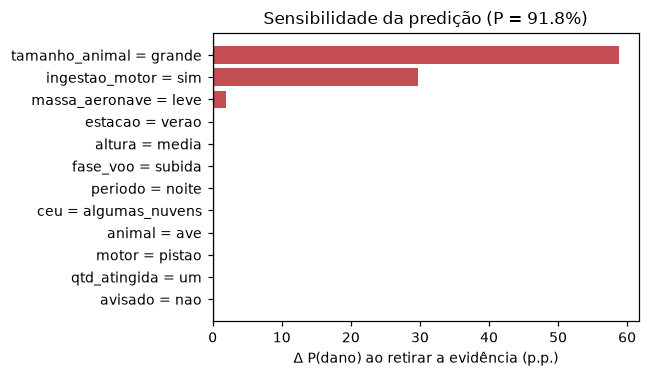

,Variável,Estado,P(dano) (%)
0,tamanho_animal,pequeno,19.8
1,tamanho_animal,medio,52.7
2,tamanho_animal,grande (caso),91.8
3,tamanho_animal,desconhecido,64.2
4,ingestao_motor,nao,62.0
5,ingestao_motor,sim (caso),91.8
6,massa_aeronave,leve (caso),91.8
7,massa_aeronave,media,79.8
8,massa_aeronave,pesada,65.6
9,massa_aeronave,desconhecido,50.0


In [26]:
sensibilidade = pd.DataFrame([{"Variável": c, "Estado no caso": caso[c],
                               "P sem ela (%)": 100 * p_dano({k: v for k, v in caso.items() if k != c}),
                               } for c in EVIDENCIAS])
sensibilidade["Δ (p.p.)"] = 100 * p_caso - sensibilidade["P sem ela (%)"]
sensibilidade = sensibilidade.reindex(sensibilidade["Δ (p.p.)"].abs().sort_values(ascending=False).index)
sensibilidade = sensibilidade.round(2)
salvar_tab(sensibilidade, "tab_sensibilidade")
display(sensibilidade)

fig, ax = plt.subplots(figsize=(5, 3.4))
cores = ["#C44E52" if d > 0 else "#4C72B0" for d in sensibilidade["Δ (p.p.)"]]
ax.barh(sensibilidade["Variável"] + " = " + sensibilidade["Estado no caso"], sensibilidade["Δ (p.p.)"], color=cores)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Δ P(dano) ao retirar a evidência (p.p.)")
ax.set_title(f"Sensibilidade da predição (P = {100 * p_caso:.1f}%)")
salvar_fig(fig, "fig_tornado")
plt.show()

influentes = sensibilidade["Variável"].head(3).tolist()
linhas = []
for c in influentes:
    for s in STATE_NAMES[c]:
        linhas.append({"Variável": c, "Estado": s + (" (caso)" if s == caso[c] else ""),
                       "P(dano) (%)": round(100 * p_dano({**caso, c: s}), 1)})
tab_estados = pd.DataFrame(linhas)
salvar_tab(tab_estados, "tab_sensibilidade_estados")
display(tab_estados)

### 6.3 Caminhos de influência

Uma evidência só influencia o alvo se houver um caminho ativo (d-conectado) entre as duas no grafo. A tabela abaixo
mostra, para cada evidência, se ela está d-conectada a `houve_dano` quando não há outra evidência e quando o resto da
evidência é conhecido, além do caminho mais curto entre as duas.

,Evidência,d-conectada (sem evidência),d-conectada (dado o resto),Caminho mais curto
0,estacao,True,False,estacao → altura; altura → tamanho_animal; tam...
1,periodo,True,False,periodo → altura; altura → tamanho_animal; tam...
2,fase_voo,True,False,fase_voo → efeito_voo; efeito_voo ← houve_dano
3,altura,True,False,altura → tamanho_animal; tamanho_animal → houv...
4,ceu,True,False,ceu → tamanho_animal; tamanho_animal → houve_dano
5,massa_aeronave,True,True,massa_aeronave → houve_dano
6,motor,True,False,motor ← massa_aeronave; massa_aeronave → houve...
7,animal,True,False,animal ← tamanho_animal; tamanho_animal → houv...
8,tamanho_animal,True,True,tamanho_animal → houve_dano
9,qtd_atingida,True,False,qtd_atingida ← tamanho_animal; tamanho_animal ...


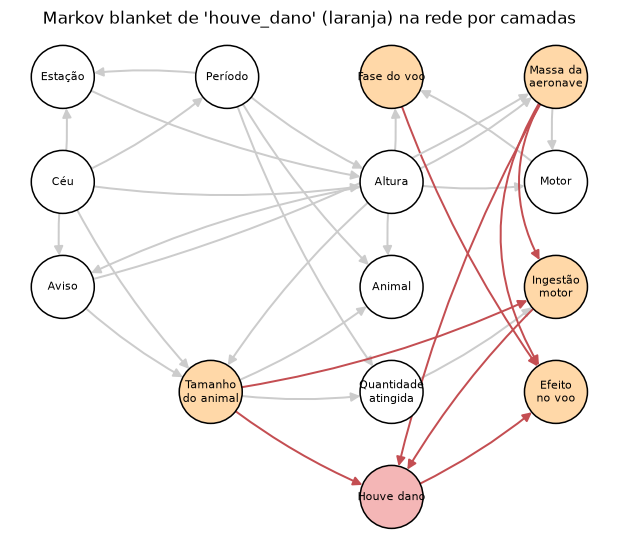

In [27]:
esqueleto = modelo.to_undirected()
linhas = []
for c in EVIDENCIAS:
    resto = [k for k in EVIDENCIAS if k != c]
    caminho = nx.shortest_path(esqueleto, c, "houve_dano")
    trechos = [f"{a} → {b}" if modelo.has_edge(a, b) else f"{a} ← {b}" for a, b in zip(caminho, caminho[1:])]
    linhas.append({"Evidência": c, "d-conectada (sem evidência)": modelo.is_dconnected(c, "houve_dano"),
                   "d-conectada (dado o resto)": modelo.is_dconnected(c, "houve_dano", observed=resto),
                   "Caminho mais curto": "; ".join(trechos)})
tab_caminhos = pd.DataFrame(linhas)
salvar_tab(tab_caminhos, "tab_caminhos", column_format="lccp{6.4cm}")
display(tab_caminhos)

cor_no = {n: ("#F4B6B6" if n == "houve_dano" else "#FFD8A8" if n in blanket else "white") for n in NOS}
cor_aresta = {(a, b): ("#C44E52" if "houve_dano" in (a, b) or (a in blanket and b in blanket) else "#CCCCCC")
              for a, b in modelo.edges()}
fig, ax = plt.subplots(figsize=(7, 6))
desenhar(modelo, ax, "Markov blanket de 'houve_dano' (laranja) na rede por camadas", cor_aresta, cor_no)
salvar_fig(fig, "fig_caminhos")
plt.show()

### 6.4 Intervenções (contrafactuais)

Observar que uma variável vale $x$ é diferente de forçar que ela valha $x$, o que se escreve $\mathrm{do}(X=x)$. Na
intervenção, cortamos as arestas que chegam em $X$, porque o valor dela passa a ser imposto de fora; assim, só os
caminhos que saem de $X$ carregam efeito. No caso escolhido, trocamos uma variável de cada vez e comparamos as duas
operações.

In [28]:
TROCAS = {"tamanho_animal": "pequeno", "ingestao_motor": "nao", "massa_aeronave": "pesada"}
linhas = []
for var, novo in TROCAS.items():
    resto = {k: v for k, v in caso.items() if k != var}
    linhas.append({"Troca": f"{var}: {caso[var]} → {novo}",
                   "Observando (%)": round(100 * p_dano({**resto, var: novo}), 1),
                   "Intervindo, do() (%)": round(100 * p_dano(resto, do={var: novo}), 1)})
tab_intervencoes = pd.DataFrame(linhas)
salvar_tab(tab_intervencoes, "tab_intervencoes")
print(f"Caso original: {100 * p_caso:.1f}%")
display(tab_intervencoes)

Caso original: 91.8%


,Troca,Observando (%),"Intervindo, do() (%)"
0,tamanho_animal: grande → pequeno,19.8,19.8
1,ingestao_motor: sim → nao,62.0,62.0
2,massa_aeronave: leve → pesada,65.6,65.6


### 6.5 Explicação em linguagem natural

O texto abaixo é montado automaticamente com os números calculados nas seções anteriores.

In [29]:
def pct(x):
    return f"{x:.1f}".replace(".", ",") + "%"

def pp(x):
    return f"{abs(x):.1f}".replace(".", ",")

def juntar(itens):
    itens = list(itens)
    return itens[0] if len(itens) == 1 else ", ".join(itens[:-1]) + " e " + itens[-1]

def explicar():
    fortes = sensibilidade[sensibilidade["Δ (p.p.)"].abs() >= 1]
    fracas = sensibilidade[(sensibilidade["Δ (p.p.)"].abs() > 0) & (sensibilidade["Δ (p.p.)"].abs() < 1)]
    irrelevantes = [c for c in EVIDENCIAS if c not in blanket]
    partes = [f"Para a colisão {registro['id']} ({registro['ano']}), a rede estima {pct(100 * p_caso)} de chance de "
              f"dano à aeronave, cerca de {p_caso / taxa_base:.0f} vezes a média da base ({pct(100 * taxa_base)})."]
    partes.append("Essa previsão só depende das evidências que estão no Markov blanket de `houve_dano`: "
                  + juntar(f"`{c} = {caso[c]}`" for c in blanket if c in caso) + ". Conhecidas essas, "
                  + juntar(f"`{c}`" for c in irrelevantes) + " deixam de fazer diferença.")
    if len(fortes):
        r = fortes.iloc[0]
        sentido = "cairia" if r["Δ (p.p.)"] > 0 else "subiria"
        partes.append(f"O que mais pesa é `{r['Variável']} = {r['Estado no caso']}`: sem essa informação, a estimativa "
                      f"{sentido} para {pct(r['P sem ela (%)'])}, {pp(r['Δ (p.p.)'])} pontos percentuais de diferença.")
    if len(fortes) > 1:
        partes.append("Em seguida vêm " + juntar(f"`{r['Variável']} = {r['Estado no caso']}` (sem ela, "
                                                 f"{pct(r['P sem ela (%)'])})" for _, r in fortes.iloc[1:].iterrows())
                      + ".")
    if len(fracas):
        partes.append(juntar(f"`{c}`" for c in fracas["Variável"]) + " mudam a estimativa em menos de um ponto percentual.")
    for _, r in tab_intervencoes.iterrows():
        variavel, troca = r["Troca"].split(": ")
        antes, depois = troca.split(" → ")
        obs, do = pct(r["Observando (%)"]), pct(r["Intervindo, do() (%)"])
        inicio = f"Se `{variavel}` fosse `{depois}` em vez de `{antes}`, a rede daria "
        if obs == do:
            partes.append(inicio + f"{obs}, tanto observando a troca quanto impondo-a por intervenção.")
        else:
            partes.append(inicio + f"{obs} observando a troca e {do} impondo-a por intervenção.")
    return " ".join(partes)

texto_explicacao = explicar()
(TAB_DIR / "explicacao_caso.txt").write_text(texto_explicacao, encoding="utf-8")
texto_tex = texto_explicacao.replace("%", r"\%")
texto_tex = re.sub(r"`([^`]+)`", lambda m: r"\texttt{" + m.group(1).replace("_", r"\_") + "}", texto_tex)
(TAB_DIR / "explicacao_caso.tex").write_text(texto_tex, encoding="utf-8")
display(Markdown(texto_explicacao))

Para a colisão 1577229 (2024), a rede estima 91,8% de chance de dano à aeronave, cerca de 12 vezes a média da base (7,7%). Essa previsão só depende das evidências que estão no Markov blanket de `houve_dano`: `fase_voo = subida`, `massa_aeronave = leve`, `tamanho_animal = grande` e `ingestao_motor = sim`. Conhecidas essas, `estacao`, `periodo`, `altura`, `ceu`, `motor`, `animal`, `qtd_atingida` e `avisado` deixam de fazer diferença. O que mais pesa é `tamanho_animal = grande`: sem essa informação, a estimativa cairia para 33,1%, 58,8 pontos percentuais de diferença. Em seguida vêm `ingestao_motor = sim` (sem ela, 62,1%) e `massa_aeronave = leve` (sem ela, 90,0%). Se `tamanho_animal` fosse `pequeno` em vez de `grande`, a rede daria 19,8%, tanto observando a troca quanto impondo-a por intervenção. Se `ingestao_motor` fosse `nao` em vez de `sim`, a rede daria 62,0%, tanto observando a troca quanto impondo-a por intervenção. Se `massa_aeronave` fosse `pesada` em vez de `leve`, a rede daria 65,6%, tanto observando a troca quanto impondo-a por intervenção.

### 6.6 Um caso em que a rede errou

O caso acima é fácil de explicar: entre as colisões com dano, é aquela em que a rede tinha mais certeza. Para ver os
limites do modelo, fazemos o contrário. Entre as colisões que tiveram dano e não têm nenhum estado `desconhecido`,
escolhemos aquela em que a rede deu a menor probabilidade de dano, ou seja, um falso negativo.

In [30]:
# Entre as colisões com dano e sem estados desconhecidos, a de menor probabilidade prevista pela rede.
com_dano = df[(df["houve_dano"] == "sim") & (df[EVIDENCIAS] != "desconhecido").all(axis=1)]
combinacoes2 = com_dano.groupby(EVIDENCIAS, observed=True).size().reset_index(name="n")
combinacoes2["p_dano"] = [p_dano({c: str(r[c]) for c in EVIDENCIAS}) for _, r in combinacoes2.iterrows()]
escolha2 = combinacoes2.sort_values(["p_dano", "n"], ascending=[True, False]).iloc[0]
caso2 = {c: str(escolha2[c]) for c in EVIDENCIAS}
iguais = (df[EVIDENCIAS].astype(str) == pd.Series(caso2)).all(axis=1)
registro2 = df[iguais & (df["houve_dano"] == "sim")].iloc[0]
p_caso2 = p_dano(caso2)
print(f"Registro FAA {registro2['id']} (ano {registro2['ano']}): P(dano | evidência) = {100 * p_caso2:.1f}%; "
      f"nível de dano real: {registro2['nivel_dano']}; efeito no voo real: {registro2['efeito_voo']}")
print(f"Colisões com exatamente a mesma evidência: {int(iguais.sum())}, das quais {int(escolha2['n'])} com dano")
display(pd.Series(caso2, name="evidência").to_frame())

# Perfil dos pais de houve_dano: quantas colisões parecidas existem e com que frequência houve dano nelas?
pais_dano = sorted(modelo.predecessors("houve_dano"))
perfil = (df[pais_dano].astype(str) == pd.Series({p: caso2[p] for p in pais_dano})).all(axis=1)
print(f"Perfil {', '.join(f'{p}={caso2[p]}' for p in pais_dano)}: {int(perfil.sum()):,} colisões, "
      f"{100 * (df.loc[perfil, 'houve_dano'] == 'sim').mean():.1f}% com dano")

# Quais trocas de um único estado mais aumentariam a probabilidade prevista?
trocas2 = pd.DataFrame([{"Variável": c, "Estado no caso": caso2[c], "Troca para": s,
                         "P(dano) (%)": round(100 * p_dano({**caso2, c: s}), 1)}
                        for c in EVIDENCIAS for s in STATE_NAMES[c] if s not in (caso2[c], "desconhecido")])
trocas2 = trocas2.sort_values("P(dano) (%)", ascending=False).head(6).reset_index(drop=True)
salvar_tab(trocas2, "tab_caso2_trocas")
display(trocas2)

# E se a rede soubesse o que aconteceu depois da colisão?
p_com_efeito = p_dano({**caso2, "efeito_voo": registro2["efeito_voo"]})
print(f"Acrescentando efeito_voo = {registro2['efeito_voo']}: P(dano) = {100 * p_com_efeito:.1f}%")
for efeito in STATE_NAMES["efeito_voo"]:
    print(f"   se efeito_voo = {efeito:20s} P(dano) = {100 * p_dano({**caso2, 'efeito_voo': efeito}):.1f}%")

Registro FAA 971157 (ano 2019): P(dano | evidência) = 1.9%; nível de dano real: leve; efeito no voo real: nenhum
Colisões com exatamente a mesma evidência: 202, das quais 7 com dano


,evidência
estacao,outono
periodo,noite
fase_voo,aproximacao
altura,alta
ceu,sem_nuvens
massa_aeronave,pesada
motor,jato
animal,ave
tamanho_animal,pequeno
qtd_atingida,um


Perfil ingestao_motor=nao, massa_aeronave=pesada, tamanho_animal=pequeno: 31,284 colisões, 1.9% com dano


,Variável,Estado no caso,Troca para,P(dano) (%)
0,tamanho_animal,pequeno,grande,30.7
1,tamanho_animal,pequeno,medio,11.8
2,ingestao_motor,nao,sim,10.5
3,massa_aeronave,pesada,leve,6.5
4,massa_aeronave,pesada,media,3.2
5,periodo,noite,dia,1.9


Acrescentando efeito_voo = nenhum: P(dano) = 1.9%
   se efeito_voo = nenhum               P(dano) = 1.9%
   se efeito_voo = pouso_precaucao      P(dano) = 17.1%
   se efeito_voo = decolagem_abortada   P(dano) = 28.2%
   se efeito_voo = desligamento_motor   P(dano) = 52.5%
   se efeito_voo = outro                P(dano) = 19.6%


**Discussão.** A colisão 971157, de 2019, foi entre um jato pesado e uma ave pequena, à noite, na aproximação, sem
ingestão pelo motor. A rede deu 1,9% de chance de dano, e mesmo assim houve dano (leve, sem efeito no voo). Isso não
quer dizer que a rede esteja mal calibrada. Na base há 31.284 colisões com os mesmos valores dos pais do dano (aeronave
pesada, animal pequeno, sem ingestão), e 1,9% delas tiveram dano. Entre as 202 colisões com toda a evidência idêntica,
7 tiveram dano. A rede acertou a frequência; esta colisão é que estava entre as poucas com dano.

Nenhuma troca isolada de evidência explicaria o dano com folga. A maior mudança seria a ave ser grande (30,7%); com
ingestão pelo motor, a estimativa iria a 10,5%, e com aeronave leve, a 6,5%. Saber o que aconteceu depois também não
ajudaria: com `efeito_voo = nenhum`, que foi o caso, a probabilidade continua em 1,9%. Se o piloto tivesse feito um
pouso de precaução, ela subiria para 17,1%, e com desligamento do motor, para 52,5%.

O erro, então, não vem da estrutura nem dos parâmetros, e sim das variáveis disponíveis. O que separa essas 7 colisões
das outras 195 não está na rede: a parte da aeronave que foi atingida e a velocidade no impacto, que a FAA registra mas
que deixamos de fora, ou a espécie exata, já que o tamanho é uma estimativa de quem faz o relato. Uma rede bayesiana só
raciocina sobre o que foi medido. Para colisões de rotina como esta, o melhor que ela pode fazer é devolver a taxa de
dano de casos parecidos.

**Discussão.** A colisão 1577229, de 2024, foi com uma ave grande, durante a subida, numa aeronave leve a pistão, e
o animal entrou no motor. A rede dá 91,8% de chance de dano, cerca de 12 vezes a média, o que não surpreende, já que
escolhemos o caso entre colisões que de fato tiveram dano.

Nessa rede, a explicação fica bem direta. Os três pais de `houve_dano` estão na evidência, então a predição é
simplesmente uma linha da tabela de probabilidade: P(dano | ingestão = sim, massa = leve, tamanho = grande) = 91,8%. O
Markov blanket inclui ainda `fase_voo` e `efeito_voo`, mas, como o efeito no voo não foi observado, a fase também não
interfere. Todas as outras variáveis ficam d-separadas do dano (veja a coluna "d-conectada (dado o resto)" da tabela
de caminhos).

A análise de sensibilidade mostra o que mais pesa. Sem saber que a ave era grande, a estimativa cairia para 33,1%, e
sem saber da ingestão, para 62,1%. Retirar a massa quase não muda nada (90,0%), porque o motor a pistão já indica uma
aeronave leve: a rede recupera a informação que falta pelas variáveis vizinhas. Trocando os estados, uma ave pequena
levaria a 19,8% e uma média, a 52,7%. Um detalhe curioso é que o tamanho `desconhecido` dá 64,2%, mais que o tamanho
médio. Nos dados, colisões com ingestão em aeronave leve e sem o tamanho informado tiveram dano com muita frequência,
o que é de novo um efeito do jeito como os relatos são preenchidos.

Nas intervenções, observar e intervir dão o mesmo resultado nas três trocas (19,8%, 62,0% e 65,6%). Os pais de cada
variável trocada já estão na evidência (altura, céu e aviso, para o tamanho; massa, quantidade e tamanho, para a
ingestão; altura e aviso, para a massa), então não sobra caminho pela porta dos fundos. Na rede livre isso não
funcionava: lá a ingestão era filha do dano, e impor que não houve ingestão não mudava em nada a probabilidade de dano.
Com a ordem por camadas, `do(ingestao_motor = nao)` passa a dizer o que se espera, que sem ingestão o risco cai, no
caso de 91,8% para 62,0%.

## 7. Arquivos gerados

Lista das figuras (PDF e PNG) e das tabelas (LaTeX) usadas no relatório.

In [31]:
for pasta in (FIG_DIR, TAB_DIR):
    print(pasta.resolve())
    for arq in sorted(pasta.glob("*")):
        if arq.suffix in (".pdf", ".tex", ".txt"):
            print("  ", arq.name)

/home/bruno_admin/tp3-redes-bayesianas/relatorio/figuras
   fig_caminhos.pdf
   fig_comparacao.pdf
   fig_q1.pdf
   fig_rede_chowliu.pdf
   fig_rede_elicitada.pdf
   fig_rede_hc.pdf
   fig_rede_hc_camadas.pdf
   fig_taxa_dano_por_estado.pdf
   fig_tornado.pdf
/home/bruno_admin/tp3-redes-bayesianas/relatorio/tabelas
   explicacao_caso.tex
   explicacao_caso.txt
   tab_arestas_so_cl.tex
   tab_arestas_so_hc.tex
   tab_arestas_so_hc_camadas.tex
   tab_caminhos.tex
   tab_caso2_trocas.tex
   tab_comparacao_arestas.tex
   tab_cpd_houve_dano.tex
   tab_estimadores.tex
   tab_funil.tex
   tab_intervencoes.tex
   tab_metricas_estruturas.tex
   tab_q1.tex
   tab_q2.tex
   tab_q3.tex
   tab_q4.tex
   tab_sensibilidade.tex
   tab_sensibilidade_estados.tex
   tab_tercis_altura.tex
   tab_variante_q2.tex
   tab_variaveis.tex
